In [1]:
"""
=============================================================================
fusion_train_v1.py  —  SchNet (audio) + Linguistic v11 (transcripts) Fusion
                        for PHQ-8 Depression Prediction

ARCHITECTURE:
  • SchNet  → sigmoid logit  (trained on audio, frozen or fine-tuned)
  • Linguistic v11 → calibrated probability  (frozen sklearn pipeline)
  • Fusion head: [schnet_logit, ling_prob, |schnet_logit - ling_prob|, product]
                  → 2-layer MLP → PHQ-8 score + binary label

FUSION STRATEGY:
  • Learned weighted fusion via a small MLP (4 meta-features → hidden → output)
  • Trains ONLY the fusion head; both base models stay frozen
  • Binary cross-entropy loss + MSE severity loss (multi-task)
  • LOO-CV on training set for threshold selection
  • Saves full bundle: schnet state, ling bundle, fusion weights, thresholds

FILE PATHS  (edit the block below):
  SCHNET_CKPT   = path to best_schnet_depression_dev.pth  (or per-fold .pth)
  LING_PKL      = path to depression_model_v11.pkl
  TRAIN_ZIP     = path to depression_transcripts.zip
  TRAIN_META    = path to train_split_Depression.csv
  AUDIO_DIR     = directory containing <pid>/<pid>_AUDIO.wav
  FUSION_SAVE   = where to write fusion_model_v1.pkl
=============================================================================
"""

import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "transformers", "torch", "torchaudio", "scikit-learn",
                "pandas", "numpy", "tqdm", "vaderSentiment"], check=True)

import os, re, glob, zipfile, pickle, warnings, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve, auc,
                             mean_absolute_error, r2_score)
from sklearn.model_selection import LeaveOneOut
from tqdm import tqdm
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════════════════════════
#  ▶  EDIT PATHS HERE
# ══════════════════════════════════════════════════════════════
SCHNET_CKPT = "/kaggle/input/models/schizospeech/schnet-dep/pytorch/default/1/fold_1_schnet.pth"

LING_PKL = "/kaggle/input/models/schizospeech/ling-dep/pytorch/default/1/depression_model_v11.pkl"

TRAIN_META = "/kaggle/input/datasets/schizospeech/depression-diac-woz/DEPRESSION_DATASET/train_split_Depression_AVEC2017.csv"

AUDIO_DIR = "/kaggle/input/datasets/schizospeech/depression-diac-woz/DEPRESSION_DATASET/Train_Audios"

FUSION_SAVE = "/kaggle/working/fusion_model_v1.pkl"

EXTRACT_TO = "/kaggle/working/dep_transcripts_fusion"

SEED    = 42
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TARGET_SR = 16_000
SEG_SECS  = 30          # seconds per audio segment for SchNet
N_SEGS    = 5           # segments to average at inference
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"Device: {DEVICE}")

# ══════════════════════════════════════════════════════════════
#  1.  SchNet architecture  (reverse-engineered from fold_1_schnet.pth)
#
#  Layer map (verified by loading checkpoint with strict=False,
#  zero missing non-mel keys, zero unexpected keys):
#
#  conv1a/1b : Block1  1→32→32    no stride
#  conv2a/2b : Block2  32→64→64   stride-2 on conv2a
#  conv3a/3b : Block3  64→128→128 stride-2 on conv3a
#  conv4a/4b : Block4  128→256→256 stride-2 on conv4a
#  skip1     : 32→256  stride-8  (block1 output → after block4)
#  skip2     : 64→256  stride-4  (block2 output → after block4)
#  skip3     : 128→256 stride-2  (block3 output → after block4)
#  concat([x4, s1, s2, s3]) → 1024ch
#  conv5     : 1024→256
#  conv6-8   : 256→256 ×3
#  attention : CBAM (channel_fc + spatial_conv + post_conv)
#  classifier: [AvgPool, BN1d, Linear256→128, ReLU, Dropout, Linear128→1]
# ══════════════════════════════════════════════════════════════
class CBAM(nn.Module):
    """Channel-and-spatial attention matching checkpoint key names."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(channels // reduction, channels, 1, bias=False),
        )
        self.spatial_conv = nn.Conv2d(2, 1, 7, padding=3, bias=False)
        self.post_conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x):
        avg = x.mean(dim=(2, 3), keepdim=True)
        mx  = x.amax(dim=(2, 3), keepdim=True)
        ca  = torch.sigmoid(self.channel_fc(avg) + self.channel_fc(mx))
        x   = x * ca
        sa  = torch.sigmoid(self.spatial_conv(
            torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], dim=1)))
        x   = x * sa
        return F.relu(self.post_conv(x))


class SchNet(nn.Module):
    def __init__(self, n_mels=64, n_fft=1024, hop=512, dropout=0.4):
        super().__init__()
        # Mel front-end (not saved in checkpoint — torchaudio stateless buffers
        # are excluded; we recompute at runtime)
        self.mel = T.MelSpectrogram(sample_rate=TARGET_SR, n_fft=n_fft,
                                    hop_length=hop, n_mels=n_mels)
        self.db  = T.AmplitudeToDB(top_db=80)

        # Encoder blocks
        self.conv1a = nn.Sequential(nn.Conv2d(1,  32, 3, padding=1, bias=False), nn.BatchNorm2d(32))
        self.conv1b = nn.Sequential(nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32))
        self.conv2a = nn.Sequential(nn.Conv2d(32, 64, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(64))
        self.conv2b = nn.Sequential(nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64))
        self.conv3a = nn.Sequential(nn.Conv2d(64,  128, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(128))
        self.conv3b = nn.Sequential(nn.Conv2d(128, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128))
        self.conv4a = nn.Sequential(nn.Conv2d(128, 256, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv4b = nn.Sequential(nn.Conv2d(256, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256))

        # Skip connections (project earlier feature maps to 256ch at block4 spatial size)
        self.skip1 = nn.Sequential(nn.Conv2d(32,  256, 1, stride=8, bias=False), nn.BatchNorm2d(256))
        self.skip2 = nn.Sequential(nn.Conv2d(64,  256, 1, stride=4, bias=False), nn.BatchNorm2d(256))
        self.skip3 = nn.Sequential(nn.Conv2d(128, 256, 1, stride=2, bias=False), nn.BatchNorm2d(256))

        # Post-fusion convs (conv5 fuses 4×256=1024ch)
        self.conv5 = nn.Sequential(nn.Conv2d(1024, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv6 = nn.Sequential(nn.Conv2d(256,  256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv7 = nn.Sequential(nn.Conv2d(256,  256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv8 = nn.Sequential(nn.Conv2d(256,  256, 3, padding=1, bias=False), nn.BatchNorm2d(256))

        # CBAM attention
        self.attention = CBAM(256, reduction=16)

        # Classifier head
        # Index layout matches checkpoint: [0]=Pool [1]=BN1d [2]=Linear [3]=ReLU [4]=Dropout [5]=Linear
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.BatchNorm1d(256),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, wav):
        x = self.db(self.mel(wav)).unsqueeze(1)     # (B, 1, n_mels, T)

        x1 = F.relu(self.conv1a(x))
        x1 = F.relu(self.conv1b(x1))

        x2 = F.relu(self.conv2a(x1))
        x2 = F.relu(self.conv2b(x2))

        x3 = F.relu(self.conv3a(x2))
        x3 = F.relu(self.conv3b(x3))

        x4 = F.relu(self.conv4a(x3))
        x4 = F.relu(self.conv4b(x4))

        fused = torch.cat([x4, self.skip1(x1), self.skip2(x2), self.skip3(x3)], dim=1)

        out = F.relu(self.conv5(fused))
        out = F.relu(self.conv6(out))
        out = F.relu(self.conv7(out))
        out = F.relu(self.conv8(out))
        out = self.attention(out)

        # Classifier: pool → flatten → BN → Linear → ReLU → Dropout → Linear
        out = self.classifier[0](out).flatten(1)    # AdaptiveAvgPool + flatten
        out = self.classifier[1](out)               # BN1d
        out = self.classifier[2](out)               # Linear 256→128
        out = self.classifier[3](out)               # ReLU
        out = self.classifier[4](out)               # Dropout
        out = self.classifier[5](out)               # Linear 128→1
        return out.squeeze(1)                        # raw logit

# ══════════════════════════════════════════════════════════════
#  2.  Load SchNet checkpoint
# ══════════════════════════════════════════════════════════════
print("\nLoading SchNet checkpoint...")
schnet = SchNet().to(DEVICE)
ckpt = torch.load(SCHNET_CKPT, map_location=DEVICE)
# fold_1_schnet.pth is a raw state_dict (keys start with conv1a, attention, classifier…)
# It does NOT contain mel/db buffers (torchaudio stateless — recomputed at runtime)
if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
    state = ckpt["model_state_dict"]
elif isinstance(ckpt, dict) and "state_dict" in ckpt:
    state = ckpt["state_dict"]
else:
    state = ckpt   # raw state_dict
missing, unexpected = schnet.load_state_dict(state, strict=False)
# Only mel/db torchaudio buffers will be missing — that's expected and harmless
non_mel_missing = [k for k in missing if not k.startswith(("mel.", "db."))]
if non_mel_missing:
    raise RuntimeError(f"Unexpected missing keys (architecture mismatch): {non_mel_missing}")
if unexpected:
    raise RuntimeError(f"Unexpected keys in checkpoint: {unexpected}")
schnet.eval()
for p in schnet.parameters():
    p.requires_grad = False
print(f"  SchNet loaded ✓  (mel/db buffers recomputed at runtime — {len(missing)} buffer keys skipped)")

# ══════════════════════════════════════════════════════════════
#  3.  Load Linguistic v11 bundle
# ══════════════════════════════════════════════════════════════
print("\nLoading Linguistic v11 bundle...")
with open(LING_PKL, "rb") as f:
    ling_bundle = pickle.load(f)

ling_clf      = ling_bundle["logreg"]
ling_svd      = ling_bundle["svd"]
ling_scaler_r = ling_bundle["scaler_rich"]
ling_scaler_b = ling_bundle["scaler_bert"]
ling_platt    = ling_bundle["platt_calibrator"]
ling_mask     = ling_bundle["feature_mask"]
ling_bert_name= ling_bundle["bert_model"]
ling_iso_sev  = ling_bundle.get("iso_severity")
LING_DEP_COL  = list(ling_clf.classes_).index(1)
print(f"  Linguistic model: {type(ling_clf).__name__}  C={ling_clf.C}")
print(f"  BERT backbone: {ling_bert_name}")

# ══════════════════════════════════════════════════════════════
#  4.  Load ClinicalBERT for linguistic features
# ══════════════════════════════════════════════════════════════
print(f"\nLoading {ling_bert_name}...")
tokenizer = AutoTokenizer.from_pretrained(ling_bert_name)
bert_enc  = AutoModel.from_pretrained(ling_bert_name).to(DEVICE)
for p in bert_enc.parameters():
    p.requires_grad = False
bert_enc.eval()

@torch.no_grad()
def embed_full_text(text, chunk_size=510, stride=256):
    token_ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    if not token_ids: return np.zeros(768, dtype=np.float32)
    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id or 0
    chunk_embs, start = [], 0
    while start < len(token_ids):
        end   = min(start + chunk_size, len(token_ids))
        chunk = [cls_id] + token_ids[start:end] + [sep_id]
        pad   = (chunk_size + 2) - len(chunk)
        ids   = chunk + [pad_id] * pad
        mask  = [1] * len(chunk) + [0] * pad
        out   = bert_enc(input_ids=torch.tensor([ids]).to(DEVICE),
                         attention_mask=torch.tensor([mask]).to(DEVICE))
        chunk_embs.append(out.last_hidden_state[:, 0, :].squeeze(0).cpu().numpy())
        if end == len(token_ids): break
        start += stride
    return np.mean(chunk_embs, axis=0).astype(np.float32)

# ══════════════════════════════════════════════════════════════
#  5.  Linguistic feature extraction  (identical to v11 training)
# ══════════════════════════════════════════════════════════════
vader = SentimentIntensityAnalyzer()

SADNESS = {"sad","sorrow","sorrowful","unhappy","miserable","grief","grieve","grieving","cry","crying","tears","weep","weeping","desolate","hopeless","despair","despairing","desperate","heartbroken","broken","empty","hollow","numb","dark","darkness","bleak","gloomy","gloom","depressed","depression","down","low","lost","alone","lonely","loneliness","isolated","isolation","worthless","useless","failure","failed","helpless","trapped","stuck","meaningless","pointless","nothing","nobody","never","always","forever","anymore"}
ANHEDONIA = {"enjoy","enjoyed","enjoyment","pleasure","fun","interest","interested","interesting","hobby","hobbies","motivation","motivated","excited","excitement","care","caring","want","wanted","desire","passion","passionate","engage","engaged","engagement","social","friends","family","activities","activity","used to"}
SOMATIC = {"sleep","sleeping","slept","insomnia","tired","tiredness","exhausted","exhaustion","fatigue","fatigued","energy","energetic","appetite","eating","weight","concentration","concentrate","focus","focused","distracted","distraction","slow","sluggish","heavy","ache","aching","pain","painful","headache","stomach","body","physical","restless","restlessness","agitated","agitation"}
COGNITIVE = {"think","thinking","thought","thoughts","mind","mental","forget","forgetting","forgetful","memory","remember","remembering","confused","confusion","unclear","difficult","difficulty","hard","struggle","struggling","overwhelmed","overwhelming","worry","worrying","worried","ruminate","ruminating","rumination","doubt","doubting","uncertain","uncertainty","blame","blaming","regret","regretting","should","must","never","always","everyone","no one","nothing","everything"}
POS_AFFECT = {"good","great","happy","wonderful","love","enjoy","fine","okay","well","nice","better","best","exciting","positive","grateful","comfortable","relaxed","fortunate","lucky","appreciate","glad","hope","hopeful","motivated","energetic","calm","peaceful","content","pleased","satisfied","proud","confident","strong","healthy"}
DISFLUENCY = {"um","uh","uhh","umm","hmm","mhm","mm","uh-huh","hm"}
FP_WORDS   = {"i","me","my","myself","mine"}
HEDGES     = {"maybe","perhaps","possibly","probably","might","could","sometimes","kind","sort","roughly","approximately","around","about","somewhat","rather","fairly","like","i think","i guess","i suppose","i believe"}
CERTAINTY  = {"definitely","certainly","absolutely","clearly","obviously","always","never","every","all","none","must","will","know","sure","certain","exactly","completely","totally","entirely","really","truly"}
FUNCTION_WORDS = {"a","an","the","is","are","was","were","be","been","being","have","has","had","do","does","did","will","would","could","should","may","might","shall","can","and","but","or","nor","for","yet","so","at","by","for","from","in","into","of","on","to","with","i","me","my","we","our","you","your","he","she","it","they","them","their","this","that","these","those","not","no","if","as","than","then","when","while","where","who","which","what","how","so","just","also"}
SUBORD_CONJ = {"because","although","though","even","while","since","if","unless","until","when","whenever","where","wherever","whether","as","after","before","once","so","than","that","despite","however","whereas"}
PHQ_DOMAINS = [{"little","interest","pleasure","enjoy"},{"feeling","down","depressed","hopeless"},{"sleep","sleeping","slept","insomnia","oversleep"},{"tired","energy","fatigue","exhausted"},{"appetite","eating","weight","overeating"},{"bad","failure","guilty","disappointment","let","down"},{"concentrate","concentration","focus","distracted"},{"slow","moving","speaking","restless","fidgety"}]
OPEN_Q_MARKERS = {"tell","describe","explain","how","what","why","when","where","talk"}
NOISE = re.compile(r'<[^>]+>|\[[^\]]+\]|\([^)]+\)', re.IGNORECASE)

def clean(text): return re.sub(r'\s+', ' ', NOISE.sub(' ', str(text))).strip()
def parse_time(t):
    try: return float(str(t).strip())
    except: return None
def is_open_question(text):
    first = text.lower().split()[0] if text.split() else ""
    return first in OPEN_Q_MARKERS
def turn_ttr(text):
    w = text.lower().split()
    return len(set(w)) / len(w) if len(w) >= 2 else 1.0
def turn_filler_ratio(text):
    w = text.lower().split()
    return sum(x in DISFLUENCY for x in w) / len(w) if w else 0.0
def linreg_slope(values):
    n = len(values)
    if n < 2: return 0.0
    x = np.arange(n, dtype=np.float32) - (n-1)/2.0
    y = np.array(values, dtype=np.float32) - np.mean(values)
    d = np.dot(x, x)
    return float(np.dot(x, y) / d) if d > 1e-9 else 0.0
def approx_syllables(word): return max(1, len(re.findall(r'[aeiouAEIOU]+', word)))

def load_dialogue(fpath):
    try:
        df = pd.read_csv(fpath, sep='\t', header=0,
                         names=['start_time','stop_time','speaker','value'],
                         dtype=str, on_bad_lines='skip')
        turns = []
        for _, row in df.iterrows():
            spk   = str(row['speaker']).strip().lower()
            txt   = clean(str(row['value']))
            start = parse_time(row['start_time'])
            stop  = parse_time(row['stop_time'])
            if len(txt) < 2 or not re.search(r'[a-zA-Z]', txt): continue
            if spk == 'participant':
                turns.append({'speaker':'participant','text':txt,'start':start,'stop':stop})
            elif spk in ('ellie','interviewer','therapist','clinician'):
                turns.append({'speaker':'interviewer','text':txt,'start':start,'stop':stop})
        return turns if turns else None
    except: return None

def extract_ling_features(rec):
    """Returns raw 107-dim vector (feature_mask applied later)."""
    turns = rec["turns"]; patient_text = rec["patient_text"]
    words = patient_text.lower().split()
    sentences = [s.strip() for s in re.split(r'[.!?]+', patient_text) if s.strip()]
    n_words = max(len(words), 1); n_sents = max(len(sentences), 1)
    sent_lens = [len(s.split()) for s in sentences] or [0]
    pat_turns = [t for t in turns if t['speaker'] == 'participant']
    int_turns = [t for t in turns if t['speaker'] == 'interviewer']
    n_pat = max(len(pat_turns), 1); n_int = max(len(int_turns), 1)

    ttr = len(set(words)) / n_words
    avg_word_len = float(np.mean([len(w) for w in words])) if words else 0.0
    avg_sent_len = n_words / n_sents; sent_std = float(np.std(sent_lens))
    sadness_count = sum(w in SADNESS for w in words)
    anhedonia_count = sum(w in ANHEDONIA for w in words)
    somatic_count = sum(w in SOMATIC for w in words)
    cognitive_count = sum(w in COGNITIVE for w in words)
    pos_count = sum(w in POS_AFFECT for w in words)
    disf_count = sum(w in DISFLUENCY for w in words)
    fp_count = sum(w in FP_WORDS for w in words)
    sadness_r = sadness_count / n_words; anhedonia_r = anhedonia_count / n_words
    somatic_r = somatic_count / n_words; cognitive_r = cognitive_count / n_words
    pos_r = pos_count / n_words; disf_r = disf_count / n_words; fp_r = fp_count / n_words
    neg_total = sadness_count + somatic_count + cognitive_count
    neg_r = neg_total / n_words; affect_ratio = neg_r / max(pos_r, 0.001)
    domain_div = int(sadness_count>0)+int(somatic_count>0)+int(cognitive_count>0)+int(anhedonia_count>0)
    log_wc = np.log1p(n_words); log_neg = np.log1p(neg_total)
    short_ratio = sum(l <= 4 for l in sent_lens) / n_sents
    sent_density = n_sents / max(log_wc, 1)
    neg_sent_ratio = sum(any(w in SADNESS or w in SOMATIC or w in COGNITIVE for w in s.lower().split()) for s in sentences) / n_sents
    mild_sig = np.clip(neg_total / 5.0, 0, 1); moderate_sig = np.clip(neg_total / 10.0, 0, 1); severe_sig = np.clip(neg_total / 15.0, 0, 1)
    wc_dict = {}
    for w in words: wc_dict[w] = wc_dict.get(w, 0) + 1
    repetition = sum(v > 2 for v in wc_dict.values()) / max(len(wc_dict), 1)
    q_ratio = patient_text.count('?') / n_sents
    pat_texts = [t['text'] for t in pat_turns]
    turn_ttrs = [turn_ttr(t) for t in pat_texts]
    mean_turn_ttr = float(np.mean(turn_ttrs)); std_turn_ttr = float(np.std(turn_ttrs)) if len(turn_ttrs) > 1 else 0.0; min_turn_ttr = float(np.min(turn_ttrs))
    turn_sent_vars = []
    for t in pat_texts:
        st = [s.strip() for s in re.split(r'[.!?]+', t) if s.strip()]
        lt = [len(s.split()) for s in st] if st else [len(t.split())]
        turn_sent_vars.append(float(np.var(lt)))
    mean_sent_var = float(np.mean(turn_sent_vars))
    turn_fillers = [turn_filler_ratio(t) for t in pat_texts]
    mean_filler = float(np.mean(turn_fillers)); std_filler = float(np.std(turn_fillers)) if len(turn_fillers) > 1 else 0.0
    seen_vocab = set(); novelties = []
    for t in pat_texts:
        tw = set(t.lower().split()); novelties.append(len(tw - seen_vocab) / max(len(tw), 1)); seen_vocab |= tw
    mean_novelty = float(np.mean(novelties)) if novelties else 1.0
    n_pairs = max(len(pat_texts) - 1, 1); monotony_count = 0
    for i in range(1, len(pat_texts)):
        pw = set(pat_texts[i-1].lower().split()); cw = set(pat_texts[i].lower().split())
        if pw and cw and len(pw & cw) / len(pw | cw) > 0.5: monotony_count += 1
    monotony_idx = monotony_count / n_pairs
    window = 5; moving_ttrs = []
    if len(pat_texts) >= window:
        for i in range(len(pat_texts) - window + 1):
            cw = " ".join(pat_texts[i:i+window]).lower().split()
            if cw: moving_ttrs.append(len(set(cw)) / len(cw))
    if moving_ttrs:
        mover_ttr_mean = float(np.mean(moving_ttrs)); mover_ttr_min = float(np.min(moving_ttrs)); mover_ttr_trend = float(moving_ttrs[-1] - moving_ttrs[0])
    else:
        mover_ttr_mean = mean_turn_ttr; mover_ttr_min = min_turn_ttr; mover_ttr_trend = 0.0
    flatness_score = (1.0 - mean_turn_ttr)*0.4 + mean_filler*0.3 + (1.0-mean_novelty)*0.3
    vader_scores = [vader.polarity_scores(t)['compound'] for t in pat_texts]
    if vader_scores:
        vader_mean = float(np.mean(vader_scores)); vader_std = float(np.std(vader_scores))
        vader_min = float(np.min(vader_scores)); vader_max = float(np.max(vader_scores))
        third_v = max(len(vader_scores)//3, 1)
        vader_early = float(np.mean(vader_scores[:third_v])); vader_late = float(np.mean(vader_scores[-third_v:]))
        vader_trend = vader_late - vader_early
        neg_turn_r = sum(s < -0.3 for s in vader_scores) / len(vader_scores)
        pos_turn_r = sum(s > 0.3 for s in vader_scores) / len(vader_scores)
        vader_range = vader_max - vader_min
    else:
        vader_mean=vader_std=vader_min=vader_max=0.0; vader_early=vader_late=vader_trend=neg_turn_r=pos_turn_r=vader_range=0.0
    latencies, speaking_rates, syllable_rates = [], [], []
    for i, t in enumerate(turns):
        if t['speaker'] == 'participant':
            n_w = len(t['text'].split())
            if t.get('start') is not None and t.get('stop') is not None:
                dur = t['stop'] - t['start']
                if dur > 0.1:
                    speaking_rates.append(n_w/dur)
                    n_syl = sum(approx_syllables(w) for w in t['text'].lower().split())
                    syllable_rates.append(n_syl/dur)
            if i > 0 and turns[i-1]['speaker'] == 'interviewer':
                ps = turns[i-1].get('stop'); cs = t.get('start')
                if ps is not None and cs is not None:
                    lat = cs - ps
                    if 0 <= lat <= 30: latencies.append(lat)
    avg_latency = float(np.mean(latencies)) if latencies else -1.0
    std_latency = float(np.std(latencies)) if len(latencies)>1 else 0.0
    avg_spk_rate = float(np.mean(speaking_rates)) if speaking_rates else -1.0
    std_spk_rate = float(np.std(speaking_rates)) if len(speaking_rates)>1 else 0.0
    long_pause_r = sum(l > 3.0 for l in latencies) / max(len(latencies), 1)
    avg_syl_rate = float(np.mean(syllable_rates)) if syllable_rates else -1.0
    lat_trend = linreg_slope(latencies) if len(latencies) >= 3 else 0.0
    spk_rate_trend = linreg_slope(speaking_rates) if len(speaking_rates) >= 3 else 0.0
    pat_turn_lens = [len(t['text'].split()) for t in pat_turns]
    avg_pat_len = float(np.mean(pat_turn_lens)); std_pat_len = float(np.std(pat_turn_lens)) if len(pat_turn_lens)>1 else 0.0
    short_turns = sum(l <= 5 for l in pat_turn_lens) / n_pat; long_turns = sum(l > 50 for l in pat_turn_lens) / n_pat
    int_turn_lens = [len(t['text'].split()) for t in int_turns]
    total_pat_wds = sum(pat_turn_lens); total_int_wds = sum(int_turn_lens) if int_turn_lens else 1
    talk_ratio = total_pat_wds / max(total_pat_wds + total_int_wds, 1)
    elaborations, open_elabs, closed_elabs, elab_seq = [], [], [], []
    for i, t in enumerate(turns):
        if t['speaker'] == 'participant' and i > 0:
            prev = turns[i-1]
            if prev['speaker'] == 'interviewer':
                ratio = len(t['text'].split()) / max(len(prev['text'].split()), 1)
                elaborations.append(ratio); elab_seq.append(ratio)
                (open_elabs if is_open_question(prev['text']) else closed_elabs).append(ratio)
    if elaborations:
        avg_elab = float(np.mean(elaborations)); std_elab = float(np.std(elaborations)) if len(elaborations)>1 else 0.0
        q25_elab = float(np.percentile(elaborations,25)); q75_elab = float(np.percentile(elaborations,75))
        iqr_elab = q75_elab - q25_elab; min_elab = float(np.min(elaborations))
    else:
        avg_elab=std_elab=q25_elab=q75_elab=iqr_elab=min_elab=1.0
    avg_open_elab = float(np.mean(open_elabs)) if open_elabs else 1.0
    avg_closed_elab = float(np.mean(closed_elabs)) if closed_elabs else 1.0
    open_closed_ratio = avg_open_elab / max(avg_closed_elab, 0.1)
    open_q_frac = sum(is_open_question(t['text']) for t in int_turns) / max(n_int, 1)
    elaboration_decline = linreg_slope(elab_seq) if len(elab_seq) >= 3 else 0.0
    third = max(len(words)//3, 1)
    neg_early = sum(w in SADNESS or w in SOMATIC for w in words[:third]) / third
    neg_late = sum(w in SADNESS or w in SOMATIC for w in words[-third:]) / third
    neg_trend = neg_late - neg_early
    def tnd(ts):
        aw = " ".join(t['text'] for t in ts).lower().split()
        return sum(w in SADNESS for w in aw) / max(len(aw), 1)
    q_sz = max(n_pat//4, 1)
    neg_q1=tnd(pat_turns[:q_sz]); neg_q2=tnd(pat_turns[q_sz:2*q_sz]); neg_q3=tnd(pat_turns[2*q_sz:3*q_sz]); neg_q4=tnd(pat_turns[3*q_sz:])
    neg_q_range = max(neg_q1,neg_q2,neg_q3,neg_q4) - min(neg_q1,neg_q2,neg_q3,neg_q4)
    phq_hits = sum(any(w in d for w in words) for d in PHQ_DOMAINS)
    phq_coverage = phq_hits / 8.0
    subord_count = sum(w in SUBORD_CONJ for w in words)
    clause_ratio = subord_count / n_sents
    long_sents_list = [l for l in sent_lens if l > 10]
    sentence_complexity = float(np.mean(long_sents_list)) if long_sents_list else 0.0
    lexical_density = sum(1 for w in words if w not in FUNCTION_WORDS) / n_words
    hedging_ratio = sum(1 for w in words if w in HEDGES) / n_words
    certainty_ratio = sum(1 for w in words if w in CERTAINTY) / n_words
    turn_len_trend = linreg_slope(pat_turn_lens) if len(pat_turn_lens) >= 3 else 0.0
    repeat_count = 0
    for i, t in enumerate(turns):
        if t['speaker'] == 'interviewer' and i > 0:
            prev = turns[i-1]
            if prev['speaker'] == 'participant':
                pw = set(prev['text'].lower().split()) - FUNCTION_WORDS
                iw = set(t['text'].lower().split()) - FUNCTION_WORDS
                if pw and iw and len(pw & iw)/max(len(pw),1) > 0.2: repeat_count += 1
    int_repeat_rate = repeat_count / max(n_int, 1)

    return np.array([
        ttr, avg_word_len, avg_sent_len, sent_std,
        sadness_r, anhedonia_r, somatic_r, cognitive_r, pos_r, disf_r, fp_r, affect_ratio,
        log_wc, log_neg, short_ratio, sent_density, neg_sent_ratio, repetition, q_ratio,
        mild_sig, moderate_sig, severe_sig, sadness_r*fp_r, domain_div/4.0, neg_r*fp_r,
        vader_mean, vader_std, vader_min, vader_max, vader_early, vader_late, vader_trend,
        neg_turn_r, pos_turn_r, vader_mean*fp_r, vader_range,
        avg_latency, std_latency, avg_spk_rate, std_spk_rate, long_pause_r,
        avg_syl_rate, std_latency, lat_trend, spk_rate_trend, std_spk_rate,
        avg_pat_len, std_pat_len, short_turns, long_turns, talk_ratio,
        float(n_pat), float(n_int), float(n_pat)/max(float(len(turns)),1),
        phq_coverage, open_q_frac,
        avg_elab, std_elab, q25_elab, q75_elab, iqr_elab, min_elab,
        avg_open_elab, avg_closed_elab, open_closed_ratio, elaboration_decline,
        neg_q1, neg_q2, neg_q3, neg_q4, neg_q_range, neg_early, neg_late, neg_trend,
        np.log1p(sadness_count), np.log1p(somatic_count), np.log1p(cognitive_count),
        np.log1p(anhedonia_count), np.log1p(disf_count), np.log1p(fp_count), np.log1p(n_words),
        mean_turn_ttr, std_turn_ttr, min_turn_ttr, mean_sent_var, mean_filler, std_filler,
        mean_novelty, monotony_idx, mover_ttr_mean, mover_ttr_min, mover_ttr_trend,
        flatness_score, vader_range*(1.0-mean_turn_ttr),
        clause_ratio, sentence_complexity, lexical_density, hedging_ratio, certainty_ratio,
        turn_len_trend, int_repeat_rate,
    ], dtype=np.float32)

# ══════════════════════════════════════════════════════════════
#  6.  Audio loading & SchNet inference
# ══════════════════════════════════════════════════════════════
_resamplers = {}

def get_resampler(orig_sr):
    if orig_sr not in _resamplers:
        _resamplers[orig_sr] = T.Resample(orig_sr, TARGET_SR)
    return _resamplers[orig_sr]

def load_audio_segments(fpath, n_segs=N_SEGS, seg_secs=SEG_SECS):
    """Load audio, resample, return list of [1, T] tensors (one per segment)."""
    try:
        wav, sr = torchaudio.load(fpath)
    except Exception as e:
        print(f"  ⚠ Audio load failed {fpath}: {e}")
        return None
    if wav.shape[0] > 1:
        wav = wav.mean(dim=0, keepdim=True)
    if sr != TARGET_SR:
        wav = get_resampler(sr)(wav)
    seg_len = int(seg_secs * TARGET_SR)
    total   = wav.shape[1]
    if total < seg_len:
        # Pad short files
        wav = F.pad(wav, (0, seg_len - total))
        return [wav]
    # Evenly spaced segments (no random at inference)
    starts = np.linspace(0, total - seg_len, n_segs, dtype=int)
    return [wav[:, s:s+seg_len] for s in starts]

@torch.no_grad()
def get_schnet_prob(fpath):
    """Returns mean sigmoid probability over N_SEGS segments."""
    segs = load_audio_segments(fpath)
    if segs is None:
        return None
    probs = []
    for seg in segs:
        seg = seg.to(DEVICE)
        logit = schnet(seg.unsqueeze(0))  # [1]
        probs.append(torch.sigmoid(logit).item())
    return float(np.mean(probs))

def get_schnet_logit(fpath):
    """Returns mean raw logit over N_SEGS segments.
    load_audio_segments returns [1, T] tensors (mono, with channel dim).
    SchNet.forward expects [B, T] — so we squeeze the channel dim first.
    """
    segs = load_audio_segments(fpath)
    if segs is None:
        return None
    logits = []
    with torch.no_grad():
        for seg in segs:
            # seg: [1, T]  →  squeeze to [T]  →  unsqueeze batch to [1, T]
            wav = seg.squeeze(0).unsqueeze(0).to(DEVICE)   # [1, T]
            logit = schnet(wav).item()
            logits.append(logit)
    return float(np.mean(logits))

# ══════════════════════════════════════════════════════════════
#  7.  Linguistic pipeline inference
# ══════════════════════════════════════════════════════════════
def get_ling_prob(rec, bert_emb):
    """Apply v11 pipeline: feature_mask → scale → SVD → scale → clf → platt."""
    rich_raw = extract_ling_features(rec)                    # (107,)
    rich_masked = rich_raw[ling_mask]                        # (n_used,)
    rich_sc = ling_scaler_r.transform(rich_masked.reshape(1, -1))
    bert_svd = ling_svd.transform(bert_emb.reshape(1, -1))
    bert_sc  = ling_scaler_b.transform(bert_svd)
    X = np.concatenate([rich_sc, bert_sc], axis=1)
    raw_p = ling_clf.predict_proba(X)[0, LING_DEP_COL]
    cal_p = ling_platt.predict_proba(np.array([[raw_p]]))[0, 1]
    return float(cal_p)

# ══════════════════════════════════════════════════════════════
#  8.  Load training data
# ══════════════════════════════════════════════════════════════
print("\nLoading transcripts...")

csv_files = glob.glob(
    "/kaggle/input/datasets/schizospeech/depression-diac-woz/DEPRESSION_DATASET/Train_Transcripts/*.csv"
)

print(f"  Found {len(csv_files)} transcript files")

meta = pd.read_csv(TRAIN_META)
meta.columns = meta.columns.str.strip()

def find_transcript(pid, files):
    try: pid_int = int(float(pid))
    except: return None
    for f in files:
        nums = re.findall(r'\d+', os.path.basename(f))
        if nums and int(nums[0]) == pid_int: return f
    return None

def find_audio_file(pid, audio_dir):
    pid_str = str(int(pid)) if isinstance(pid, (int, float)) else str(pid)
    matches = glob.glob(os.path.join(audio_dir, "**", f"{pid_str}*.wav"), recursive=True)
    if not matches:
        matches = glob.glob(os.path.join(audio_dir, f"{pid_str}*.wav"))
    audio_m = [m for m in matches if "_AUDIO" in os.path.basename(m).upper()]
    return audio_m[0] if audio_m else (matches[0] if matches else None)

print("\nLoading records (transcript + audio match)...")
records = []
for _, row in meta.iterrows():
    pid    = row["Participant_ID"]
    tpath  = find_transcript(pid, csv_files)
    apath  = find_audio_file(pid, AUDIO_DIR)
    if not tpath or not apath: continue
    turns  = load_dialogue(tpath)
    if not turns: continue
    phq_score  = row["PHQ8_Score"]
    phq_binary = row["PHQ8_Binary"]
    if pd.isna(phq_score) or pd.isna(phq_binary): continue
    patient_text = " ".join(t['text'] for t in turns if t['speaker'] == 'participant')
    if len(patient_text.strip()) < 10: continue
    records.append({
        "pid": pid, "turns": turns, "patient_text": patient_text,
        "audio_path": apath,
        "phq_score": float(phq_score), "phq_binary": int(phq_binary),
    })

N = len(records)
y_bin = np.array([r["phq_binary"] for r in records])
y_scr = np.array([r["phq_score"]  for r in records])
print(f"\nMatched: {N} participants  |  Dep: {y_bin.sum()}  |  Non-dep: {(y_bin==0).sum()}")

# ══════════════════════════════════════════════════════════════
#  9.  Extract all modality scores
# ══════════════════════════════════════════════════════════════
print("\n─── Step 1: BERT embeddings ───")
bert_embs = np.array([embed_full_text(r["patient_text"]) for r in tqdm(records)])

print("\n─── Step 2: Linguistic probabilities ───")
ling_probs = np.array([get_ling_prob(r, e) for r, e in tqdm(zip(records, bert_embs))])

print("\n─── Step 3: SchNet logits ───")
schnet_logits = np.array([get_schnet_logit(r["audio_path"]) for r in tqdm(records)])
schnet_probs  = 1 / (1 + np.exp(-schnet_logits))

# Handle any None values (missing audio)
valid_mask = ~np.isnan(schnet_logits)
if not valid_mask.all():
    print(f"  ⚠ {(~valid_mask).sum()} participants missing audio, dropping...")
    records      = [r for r, v in zip(records, valid_mask) if v]
    y_bin        = y_bin[valid_mask]; y_scr = y_scr[valid_mask]
    ling_probs   = ling_probs[valid_mask]
    schnet_logits = schnet_logits[valid_mask]
    schnet_probs  = schnet_probs[valid_mask]
    N = len(records)

print(f"\nProbability summary (N={N}):")
print(f"  SchNet  probs: mean={schnet_probs.mean():.3f}  std={schnet_probs.std():.3f}  [{schnet_probs.min():.3f},{schnet_probs.max():.3f}]")
print(f"  Ling    probs: mean={ling_probs.mean():.3f}  std={ling_probs.std():.3f}  [{ling_probs.min():.3f},{ling_probs.max():.3f}]")

# ══════════════════════════════════════════════════════════════
#  10.  Fusion meta-features
# ══════════════════════════════════════════════════════════════
def make_meta_features(sch_logit, ling_p):
    """4-dim meta-feature vector for the fusion head."""
    sch_p = float(1 / (1 + np.exp(-sch_logit)))
    ling_p = float(ling_p)
    return np.array([
        sch_p,                       # SchNet probability
        ling_p,                      # Linguistic probability
        abs(sch_p - ling_p),         # disagreement signal
        sch_p * ling_p,              # product (high only if both agree depression)
    ], dtype=np.float32)

X_meta = np.array([make_meta_features(sl, lp)
                   for sl, lp in zip(schnet_logits, ling_probs)])

print(f"\nMeta-feature matrix: {X_meta.shape}")
print("  Columns: [schnet_prob, ling_prob, |diff|, product]")

# ══════════════════════════════════════════════════════════════
#  11.  Fusion MLP definition
# ══════════════════════════════════════════════════════════════
class FusionMLP(nn.Module):
    """
    4-dim meta-features → hidden → binary logit + severity regression.
    Two heads: binary (BCE) + severity (MSE), trained jointly.
    """
    def __init__(self, in_dim=4, hidden=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
        )
        self.cls_head = nn.Linear(hidden // 2, 1)   # binary
        self.reg_head = nn.Linear(hidden // 2, 1)   # severity (PHQ score)

    def forward(self, x):
        h = self.net(x)
        return self.cls_head(h).squeeze(1), self.reg_head(h).squeeze(1)

# ══════════════════════════════════════════════════════════════
#  12.  LOO-CV on fusion head  (for threshold calibration)
# ══════════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print(f"LOO-CV on Fusion MLP  (N={N})")
print('='*60)

FUSION_EPOCHS = 200
FUSION_LR     = 1e-3
FUSION_WD     = 1e-2
ALPHA_SEV     = 0.3     # weight of severity loss vs binary

loo_fusion_probs = np.zeros(N, dtype=np.float32)

for fold in tqdm(range(N), desc="Fusion LOO"):
    tr_idx = [i for i in range(N) if i != fold]
    X_tr   = torch.tensor(X_meta[tr_idx], dtype=torch.float32)
    y_tr   = torch.tensor(y_bin[tr_idx],  dtype=torch.float32)
    s_tr   = torch.tensor(y_scr[tr_idx],  dtype=torch.float32)
    X_val  = torch.tensor(X_meta[[fold]], dtype=torch.float32)

    # Class-weighted BCE
    n_pos = y_tr.sum().item(); n_neg = len(y_tr) - n_pos
    pos_w = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32)
    bce   = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    mse   = nn.MSELoss()

    model_f = FusionMLP()
    opt     = torch.optim.AdamW(model_f.parameters(), lr=FUSION_LR, weight_decay=FUSION_WD)
    sch     = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FUSION_EPOCHS)

    model_f.train()
    for epoch in range(FUSION_EPOCHS):
        opt.zero_grad()
        cls_logit, sev_pred = model_f(X_tr)
        # Normalise severity to [0,1] range for stable training
        sev_norm = s_tr / 24.0
        sev_norm_pred = torch.sigmoid(sev_pred)
        loss = bce(cls_logit, y_tr) + ALPHA_SEV * mse(sev_norm_pred, sev_norm)
        loss.backward(); opt.step(); sch.step()

    model_f.eval()
    with torch.no_grad():
        cls_logit_val, _ = model_f(X_val)
        loo_fusion_probs[fold] = torch.sigmoid(cls_logit_val).item()

print("\nFusion LOO probability distribution:")
for label, mask in [("Non-dep ", y_bin==0), ("Depressed", y_bin==1)]:
    p = loo_fusion_probs[mask]
    print(f"  {label} (n={mask.sum():2d}): mean={p.mean():.3f}  std={p.std():.3f}  [{p.min():.3f},{p.max():.3f}]")

# ══════════════════════════════════════════════════════════════
#  13.  Threshold selection
# ══════════════════════════════════════════════════════════════
from sklearn.metrics import roc_curve, auc as sk_auc
fpr_arr, tpr_arr, thresh_arr = roc_curve(y_bin, loo_fusion_probs)
roc_auc_fusion = sk_auc(fpr_arr, tpr_arr)
spec_arr = 1 - fpr_arr
youdens  = tpr_arr + spec_arr - 1
best_j   = np.argmax(youdens)
best_t   = float(thresh_arr[best_j])
best_sens = float(tpr_arr[best_j]); best_spec = float(spec_arr[best_j])

clin_t = 0.5; clin_sens = 0.0; clin_spec = 0.0
for t, sens, spec in zip(thresh_arr, tpr_arr, spec_arr):
    if spec >= 0.65 and sens > clin_sens:
        clin_sens, clin_spec, clin_t = float(sens), float(spec), float(t)

print(f"\nFusion ROC-AUC (LOO): {roc_auc_fusion:.3f}")
print(f"Youden:   {best_t:.3f}  Sens={best_sens:.3f}  Spec={best_spec:.3f}")
print(f"Clinical: {clin_t:.3f}  Sens={clin_sens:.3f}  Spec={clin_spec:.3f}")

# Classification reports
for label, thresh, pred in [
    ("0.5",      0.5,    (loo_fusion_probs >= 0.5).astype(int)),
    ("Youden",   best_t, (loo_fusion_probs >= best_t).astype(int)),
    ("Clinical", clin_t, (loo_fusion_probs >= clin_t).astype(int)),
]:
    print(f"\n── @ {thresh:.3f} ({label}) ──")
    print(classification_report(y_bin, pred, target_names=["Non-dep","Depressed"], digits=3, zero_division=0))
    cm = confusion_matrix(y_bin, pred)
    if cm.shape == (2, 2):
        tn_, fp_, fn_, tp_ = cm.ravel()
        print(f"  TN={tn_} FP={fp_} FN={fn_} TP={tp_}  Sens={tp_/max(tp_+fn_,1):.3f}  Spec={tn_/max(tn_+fp_,1):.3f}")

# Severity
iso_fus = IsotonicRegression(out_of_bounds='clip')
iso_fus.fit(loo_fusion_probs, y_scr)
sev_pred_loo = iso_fus.predict(loo_fusion_probs)
print(f"\nSeverity (isotonic, in-sample LOO) — MAE={mean_absolute_error(y_scr, sev_pred_loo):.2f}  R²={r2_score(y_scr, sev_pred_loo):.3f}")

# ══════════════════════════════════════════════════════════════
#  14.  Train final fusion model on ALL data
# ══════════════════════════════════════════════════════════════
print(f"\nTraining final fusion model on all {N} samples...")
X_all = torch.tensor(X_meta, dtype=torch.float32)
y_all = torch.tensor(y_bin, dtype=torch.float32)
s_all = torch.tensor(y_scr, dtype=torch.float32)
n_pos = y_all.sum().item(); n_neg = N - n_pos
pos_w_f = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32)
bce_f = nn.BCEWithLogitsLoss(pos_weight=pos_w_f); mse_f = nn.MSELoss()

fusion_model = FusionMLP()
opt_f = torch.optim.AdamW(fusion_model.parameters(), lr=FUSION_LR, weight_decay=FUSION_WD)
sch_f = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f, T_max=FUSION_EPOCHS)

fusion_model.train()
for epoch in range(FUSION_EPOCHS):
    opt_f.zero_grad()
    cls_logit, sev_pred = fusion_model(X_all)
    sev_norm = s_all / 24.0; sev_norm_pred = torch.sigmoid(sev_pred)
    loss = bce_f(cls_logit, y_all) + ALPHA_SEV * mse_f(sev_norm_pred, sev_norm)
    loss.backward(); opt_f.step(); sch_f.step()

fusion_model.eval()
print("Final model trained.")

# ══════════════════════════════════════════════════════════════
#  15.  Save complete fusion bundle
# ══════════════════════════════════════════════════════════════
bundle = {
    # Fusion head
    "fusion_mlp_state":  fusion_model.state_dict(),
    "fusion_mlp_config": {"in_dim": 4, "hidden": 16, "dropout": 0.3},
    # Thresholds
    "thresh_youden":     best_t,
    "thresh_clinical":   clin_t,
    # Severity
    "iso_severity":      iso_fus,
    # Performance
    "auc_loo":           roc_auc_fusion,
    "sens_youden":       best_sens,
    "spec_youden":       best_spec,
    "sens_clinical":     clin_sens,
    "spec_clinical":     clin_spec,
    # SchNet config (so inference can rebuild the model)
    "schnet_ckpt_path":  SCHNET_CKPT,
    "schnet_config":     {"n_mels": 64, "n_fft": 1024, "hop": 512,
                          "base_ch": 32, "dropout": 0.4},
    # Linguistic bundle reference
    "ling_pkl_path":     LING_PKL,
    # Inference constants
    "target_sr":         TARGET_SR,
    "n_segs":            N_SEGS,
    "seg_secs":          SEG_SECS,
    "alpha_sev":         ALPHA_SEV,
    # LOO diagnostics
    "loo_probs":         loo_fusion_probs,
    "loo_prob_mean_dep":    float(loo_fusion_probs[y_bin==1].mean()),
    "loo_prob_mean_nodep":  float(loo_fusion_probs[y_bin==0].mean()),
    "N_train":           N,
}

with open(FUSION_SAVE, "wb") as f:
    pickle.dump(bundle, f)

print(f"\nFusion bundle saved → {FUSION_SAVE}")
print(f"\n{'='*60}")
print("  FINAL SUMMARY — fusion_v1")
print('='*60)
print(f"  Fusion AUC (LOO):   {roc_auc_fusion:.3f}")
print(f"  Youden: {best_t:.3f}  Sens={best_sens:.3f}  Spec={best_spec:.3f}")
print(f"  Clinical: {clin_t:.3f}  Sens={clin_sens:.3f}  Spec={clin_spec:.3f}")
print(f"  Severity MAE (LOO): {mean_absolute_error(y_scr, sev_pred_loo):.2f}")
print('='*60)

100%|██████████| 107/107 [01:03<00:00,  1.67it/s]



Probability summary (N=107):
  SchNet  probs: mean=0.586  std=0.016  [0.540,0.613]
  Ling    probs: mean=0.280  std=0.214  [0.060,0.761]

Meta-feature matrix: (107, 4)
  Columns: [schnet_prob, ling_prob, |diff|, product]

LOO-CV on Fusion MLP  (N=107)


Fusion LOO: 100%|██████████| 107/107 [00:47<00:00,  2.23it/s]



Fusion LOO probability distribution:
  Non-dep  (n=77): mean=0.363  std=0.159  [0.104,0.776]
  Depressed (n=30): mean=0.759  std=0.151  [0.464,0.945]

Fusion ROC-AUC (LOO): 0.958
Youden:   0.485  Sens=0.967  Spec=0.844
Clinical: 0.464  Sens=1.000  Spec=0.792

── @ 0.500 (0.5) ──
              precision    recall  f1-score   support

     Non-dep      0.957     0.857     0.904        77
   Depressed      0.711     0.900     0.794        30

    accuracy                          0.869       107
   macro avg      0.834     0.879     0.849       107
weighted avg      0.888     0.869     0.873       107

  TN=66 FP=11 FN=3 TP=27  Sens=0.900  Spec=0.857

── @ 0.485 (Youden) ──
              precision    recall  f1-score   support

     Non-dep      0.985     0.844     0.909        77
   Depressed      0.707     0.967     0.817        30

    accuracy                          0.879       107
   macro avg      0.846     0.905     0.863       107
weighted avg      0.907     0.879     0.883    

Visualization

In [4]:
"""
=============================================================================
fusion_test_v1.py  —  Inference script for fusion_model_v1.pkl

PIPELINE:
  Audio  → SchNet  → sigmoid logit
  Transcript → ClinicalBERT + Rich features → v11 pipeline → calibrated prob
  [sch_p, ling_p, |diff|, product] → FusionMLP → PHQ-8 binary + severity

USAGE:
  1. Edit the PATH BLOCK below
  2. Run in Colab/Kaggle with GPU
  3. Outputs per-participant predictions + classification report
=============================================================================
"""

import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "transformers", "torch", "torchaudio", "scikit-learn",
                "pandas", "numpy", "tqdm", "vaderSentiment"], check=True)

import os, re, glob, zipfile, pickle, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, mean_absolute_error, r2_score)
from tqdm import tqdm
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════════════════════════
#  ▶  EDIT PATHS HERE
# ══════════════════════════════════════════════════════════════
FUSION_PKL = "/kaggle/working/fusion_model_v1.pkl"

SCHNET_CKPT = "/kaggle/input/models/schizospeech/schnet-dep/pytorch/default/1/fold_1_schnet.pth"

LING_PKL = "/kaggle/input/models/schizospeech/ling-dep/pytorch/default/1/depression_model_v11.pkl"

TEST_META = "/kaggle/input/datasets/schizospeech/depression-diac-woz/DEPRESSION_DATASET/full_test_split.csv"

TEST_AUDIO = "/kaggle/input/datasets/schizospeech/depression-diac-woz/DEPRESSION_DATASET/Test_Audios"

EXTRACT_TO = "/kaggle/working/test_fusion"

# ══════════════════════════════════════════════════════════════

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# ══════════════════════════════════════════════════════════════
#  1.  Load fusion bundle
# ══════════════════════════════════════════════════════════════
print("\nLoading fusion bundle...")
with open(FUSION_PKL, "rb") as f:
    fusion_bundle = pickle.load(f)

TARGET_SR     = fusion_bundle["target_sr"]
N_SEGS        = fusion_bundle["n_segs"]
SEG_SECS      = fusion_bundle["seg_secs"]
THRESH_YOUDEN = float(fusion_bundle["thresh_youden"])
THRESH_CLIN   = float(fusion_bundle["thresh_clinical"])
iso_severity  = fusion_bundle["iso_severity"]

print(f"  Train AUC (LOO):   {fusion_bundle['auc_loo']:.3f}")
print(f"  Youden threshold:  {THRESH_YOUDEN:.3f}  Sens={fusion_bundle['sens_youden']:.3f}  Spec={fusion_bundle['spec_youden']:.3f}")
print(f"  Clinical threshold:{THRESH_CLIN:.3f}  Sens={fusion_bundle['sens_clinical']:.3f}  Spec={fusion_bundle['spec_clinical']:.3f}")
print(f"  Train N:           {fusion_bundle['N_train']}")

# ══════════════════════════════════════════════════════════════
#  2.  Rebuild SchNet  (exact architecture matching fold_1_schnet.pth)
# ══════════════════════════════════════════════════════════════
class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(channels // reduction, channels, 1, bias=False),
        )
        self.spatial_conv = nn.Conv2d(2, 1, 7, padding=3, bias=False)
        self.post_conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x):
        avg = x.mean(dim=(2, 3), keepdim=True)
        mx  = x.amax(dim=(2, 3), keepdim=True)
        ca  = torch.sigmoid(self.channel_fc(avg) + self.channel_fc(mx))
        x   = x * ca
        sa  = torch.sigmoid(self.spatial_conv(
            torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], dim=1)))
        x   = x * sa
        return F.relu(self.post_conv(x))


class SchNet(nn.Module):
    def __init__(self, n_mels=64, n_fft=1024, hop=512, dropout=0.4):
        super().__init__()
        self.mel = T.MelSpectrogram(sample_rate=TARGET_SR, n_fft=n_fft,
                                    hop_length=hop, n_mels=n_mels)
        self.db  = T.AmplitudeToDB(top_db=80)
        self.conv1a = nn.Sequential(nn.Conv2d(1,  32, 3, padding=1, bias=False), nn.BatchNorm2d(32))
        self.conv1b = nn.Sequential(nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32))
        self.conv2a = nn.Sequential(nn.Conv2d(32, 64, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(64))
        self.conv2b = nn.Sequential(nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64))
        self.conv3a = nn.Sequential(nn.Conv2d(64,  128, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(128))
        self.conv3b = nn.Sequential(nn.Conv2d(128, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128))
        self.conv4a = nn.Sequential(nn.Conv2d(128, 256, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv4b = nn.Sequential(nn.Conv2d(256, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.skip1  = nn.Sequential(nn.Conv2d(32,  256, 1, stride=8, bias=False), nn.BatchNorm2d(256))
        self.skip2  = nn.Sequential(nn.Conv2d(64,  256, 1, stride=4, bias=False), nn.BatchNorm2d(256))
        self.skip3  = nn.Sequential(nn.Conv2d(128, 256, 1, stride=2, bias=False), nn.BatchNorm2d(256))
        self.conv5  = nn.Sequential(nn.Conv2d(1024, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv6  = nn.Sequential(nn.Conv2d(256,  256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv7  = nn.Sequential(nn.Conv2d(256,  256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.conv8  = nn.Sequential(nn.Conv2d(256,  256, 3, padding=1, bias=False), nn.BatchNorm2d(256))
        self.attention  = CBAM(256, reduction=16)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.BatchNorm1d(256),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, wav):
        x  = self.db(self.mel(wav)).unsqueeze(1)
        x1 = F.relu(self.conv1a(x));  x1 = F.relu(self.conv1b(x1))
        x2 = F.relu(self.conv2a(x1)); x2 = F.relu(self.conv2b(x2))
        x3 = F.relu(self.conv3a(x2)); x3 = F.relu(self.conv3b(x3))
        x4 = F.relu(self.conv4a(x3)); x4 = F.relu(self.conv4b(x4))
        fused = torch.cat([x4, self.skip1(x1), self.skip2(x2), self.skip3(x3)], dim=1)
        out = F.relu(self.conv5(fused))
        out = F.relu(self.conv6(out)); out = F.relu(self.conv7(out)); out = F.relu(self.conv8(out))
        out = self.attention(out)
        out = self.classifier[0](out).flatten(1)
        out = self.classifier[1](out); out = self.classifier[2](out)
        out = self.classifier[3](out); out = self.classifier[4](out)
        out = self.classifier[5](out)
        return out.squeeze(1)

class FusionMLP(nn.Module):
    def __init__(self, in_dim=4, hidden=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU())
        self.cls_head = nn.Linear(hidden // 2, 1)
        self.reg_head = nn.Linear(hidden // 2, 1)
    def forward(self, x):
        h = self.net(x)
        return self.cls_head(h).squeeze(1), self.reg_head(h).squeeze(1)

# Load SchNet weights
print("\nLoading SchNet...")
schnet = SchNet().to(DEVICE)
ckpt = torch.load(SCHNET_CKPT, map_location=DEVICE)
state = ckpt.get("model_state_dict", ckpt.get("state_dict", ckpt))
missing, unexpected = schnet.load_state_dict(state, strict=False)
non_mel_missing = [k for k in missing if not k.startswith(("mel.", "db."))]
if non_mel_missing:
    raise RuntimeError(f"Architecture mismatch — missing keys: {non_mel_missing}")
if unexpected:
    raise RuntimeError(f"Unexpected keys in checkpoint: {unexpected}")
schnet.eval()
for p in schnet.parameters(): p.requires_grad = False
print(f"  SchNet loaded ✓  ({len(missing)} mel/db buffer(s) recomputed at runtime)")

# Load Fusion MLP weights
print("Loading FusionMLP...")
fusion_cfg = fusion_bundle["fusion_mlp_config"]
fusion_mlp = FusionMLP(**fusion_cfg)
fusion_mlp.load_state_dict(fusion_bundle["fusion_mlp_state"])
fusion_mlp.eval()
print("  FusionMLP loaded.")

# ══════════════════════════════════════════════════════════════
#  3.  Load Linguistic v11 bundle
# ══════════════════════════════════════════════════════════════
print("\nLoading Linguistic v11...")
with open(LING_PKL, "rb") as f:
    ling_bundle = pickle.load(f)

ling_clf      = ling_bundle["logreg"]
ling_svd      = ling_bundle["svd"]
ling_scaler_r = ling_bundle["scaler_rich"]
ling_scaler_b = ling_bundle["scaler_bert"]
ling_platt    = ling_bundle["platt_calibrator"]
ling_mask     = ling_bundle["feature_mask"]
ling_bert_name= ling_bundle["bert_model"]
LING_DEP_COL  = list(ling_clf.classes_).index(1)
print(f"  BERT: {ling_bert_name}")

# Load BERT
print(f"Loading {ling_bert_name}...")
tokenizer = AutoTokenizer.from_pretrained(ling_bert_name)
bert_enc  = AutoModel.from_pretrained(ling_bert_name).to(DEVICE)
for p in bert_enc.parameters(): p.requires_grad = False
bert_enc.eval()
print("  BERT ready.")

# ══════════════════════════════════════════════════════════════
#  4.  Lexicons (identical to training — required for feature parity)
# ══════════════════════════════════════════════════════════════
vader = SentimentIntensityAnalyzer()
SADNESS = {"sad","sorrow","sorrowful","unhappy","miserable","grief","grieve","grieving","cry","crying","tears","weep","weeping","desolate","hopeless","despair","despairing","desperate","heartbroken","broken","empty","hollow","numb","dark","darkness","bleak","gloomy","gloom","depressed","depression","down","low","lost","alone","lonely","loneliness","isolated","isolation","worthless","useless","failure","failed","helpless","trapped","stuck","meaningless","pointless","nothing","nobody","never","always","forever","anymore"}
ANHEDONIA = {"enjoy","enjoyed","enjoyment","pleasure","fun","interest","interested","interesting","hobby","hobbies","motivation","motivated","excited","excitement","care","caring","want","wanted","desire","passion","passionate","engage","engaged","engagement","social","friends","family","activities","activity","used to"}
SOMATIC = {"sleep","sleeping","slept","insomnia","tired","tiredness","exhausted","exhaustion","fatigue","fatigued","energy","energetic","appetite","eating","weight","concentration","concentrate","focus","focused","distracted","distraction","slow","sluggish","heavy","ache","aching","pain","painful","headache","stomach","body","physical","restless","restlessness","agitated","agitation"}
COGNITIVE = {"think","thinking","thought","thoughts","mind","mental","forget","forgetting","forgetful","memory","remember","remembering","confused","confusion","unclear","difficult","difficulty","hard","struggle","struggling","overwhelmed","overwhelming","worry","worrying","worried","ruminate","ruminating","rumination","doubt","doubting","uncertain","uncertainty","blame","blaming","regret","regretting","should","must","never","always","everyone","no one","nothing","everything"}
POS_AFFECT = {"good","great","happy","wonderful","love","enjoy","fine","okay","well","nice","better","best","exciting","positive","grateful","comfortable","relaxed","fortunate","lucky","appreciate","glad","hope","hopeful","motivated","energetic","calm","peaceful","content","pleased","satisfied","proud","confident","strong","healthy"}
DISFLUENCY = {"um","uh","uhh","umm","hmm","mhm","mm","uh-huh","hm"}
FP_WORDS = {"i","me","my","myself","mine"}
HEDGES = {"maybe","perhaps","possibly","probably","might","could","sometimes","kind","sort","roughly","approximately","around","about","somewhat","rather","fairly","like","i think","i guess","i suppose","i believe"}
CERTAINTY = {"definitely","certainly","absolutely","clearly","obviously","always","never","every","all","none","must","will","know","sure","certain","exactly","completely","totally","entirely","really","truly"}
FUNCTION_WORDS = {"a","an","the","is","are","was","were","be","been","being","have","has","had","do","does","did","will","would","could","should","may","might","shall","can","and","but","or","nor","for","yet","so","at","by","for","from","in","into","of","on","to","with","i","me","my","we","our","you","your","he","she","it","they","them","their","this","that","these","those","not","no","if","as","than","then","when","while","where","who","which","what","how","so","just","also"}
SUBORD_CONJ = {"because","although","though","even","while","since","if","unless","until","when","whenever","where","wherever","whether","as","after","before","once","so","than","that","despite","however","whereas"}
PHQ_DOMAINS = [{"little","interest","pleasure","enjoy"},{"feeling","down","depressed","hopeless"},{"sleep","sleeping","slept","insomnia","oversleep"},{"tired","energy","fatigue","exhausted"},{"appetite","eating","weight","overeating"},{"bad","failure","guilty","disappointment","let","down"},{"concentrate","concentration","focus","distracted"},{"slow","moving","speaking","restless","fidgety"}]
OPEN_Q_MARKERS = {"tell","describe","explain","how","what","why","when","where","talk"}
NOISE = re.compile(r'<[^>]+>|\[[^\]]+\]|\([^)]+\)', re.IGNORECASE)

def clean(text): return re.sub(r'\s+', ' ', NOISE.sub(' ', str(text))).strip()
def parse_time(t):
    try: return float(str(t).strip())
    except: return None
def is_open_question(text):
    first = text.lower().split()[0] if text.split() else ""
    return first in OPEN_Q_MARKERS
def turn_ttr(text):
    w = text.lower().split(); return len(set(w)) / len(w) if len(w) >= 2 else 1.0
def turn_filler_ratio(text):
    w = text.lower().split(); return sum(x in DISFLUENCY for x in w) / len(w) if w else 0.0
def linreg_slope(values):
    n = len(values)
    if n < 2: return 0.0
    x = np.arange(n, dtype=np.float32) - (n-1)/2.0
    y = np.array(values, dtype=np.float32) - np.mean(values)
    d = np.dot(x, x); return float(np.dot(x, y) / d) if d > 1e-9 else 0.0
def approx_syllables(word): return max(1, len(re.findall(r'[aeiouAEIOU]+', word)))

def load_dialogue(fpath):
    try:
        df = pd.read_csv(fpath, sep='\t', header=0,
                         names=['start_time','stop_time','speaker','value'],
                         dtype=str, on_bad_lines='skip')
        turns = []
        for _, row in df.iterrows():
            spk = str(row['speaker']).strip().lower(); txt = clean(str(row['value']))
            start = parse_time(row['start_time']); stop = parse_time(row['stop_time'])
            if len(txt) < 2 or not re.search(r'[a-zA-Z]', txt): continue
            if spk == 'participant':
                turns.append({'speaker':'participant','text':txt,'start':start,'stop':stop})
            elif spk in ('ellie','interviewer','therapist','clinician'):
                turns.append({'speaker':'interviewer','text':txt,'start':start,'stop':stop})
        return turns if turns else None
    except: return None

def extract_ling_features(rec):
    """107-dim feature vector — identical to training."""
    turns = rec["turns"]; patient_text = rec["patient_text"]
    words = patient_text.lower().split()
    sentences = [s.strip() for s in re.split(r'[.!?]+', patient_text) if s.strip()]
    n_words = max(len(words), 1); n_sents = max(len(sentences), 1)
    sent_lens = [len(s.split()) for s in sentences] or [0]
    pat_turns = [t for t in turns if t['speaker'] == 'participant']
    int_turns = [t for t in turns if t['speaker'] == 'interviewer']
    n_pat = max(len(pat_turns), 1); n_int = max(len(int_turns), 1)
    ttr = len(set(words)) / n_words
    avg_word_len = float(np.mean([len(w) for w in words])) if words else 0.0
    avg_sent_len = n_words / n_sents; sent_std = float(np.std(sent_lens))
    sadness_count = sum(w in SADNESS for w in words); anhedonia_count = sum(w in ANHEDONIA for w in words)
    somatic_count = sum(w in SOMATIC for w in words); cognitive_count = sum(w in COGNITIVE for w in words)
    pos_count = sum(w in POS_AFFECT for w in words); disf_count = sum(w in DISFLUENCY for w in words); fp_count = sum(w in FP_WORDS for w in words)
    sadness_r = sadness_count/n_words; anhedonia_r = anhedonia_count/n_words; somatic_r = somatic_count/n_words
    cognitive_r = cognitive_count/n_words; pos_r = pos_count/n_words; disf_r = disf_count/n_words; fp_r = fp_count/n_words
    neg_total = sadness_count + somatic_count + cognitive_count
    neg_r = neg_total/n_words; affect_ratio = neg_r/max(pos_r, 0.001)
    domain_div = int(sadness_count>0)+int(somatic_count>0)+int(cognitive_count>0)+int(anhedonia_count>0)
    log_wc = np.log1p(n_words); log_neg = np.log1p(neg_total)
    short_ratio = sum(l<=4 for l in sent_lens)/n_sents; sent_density = n_sents/max(log_wc,1)
    neg_sent_ratio = sum(any(w in SADNESS or w in SOMATIC or w in COGNITIVE for w in s.lower().split()) for s in sentences)/n_sents
    mild_sig = np.clip(neg_total/5.0,0,1); moderate_sig = np.clip(neg_total/10.0,0,1); severe_sig = np.clip(neg_total/15.0,0,1)
    wc_dict = {}
    for w in words: wc_dict[w] = wc_dict.get(w,0)+1
    repetition = sum(v>2 for v in wc_dict.values())/max(len(wc_dict),1)
    q_ratio = patient_text.count('?')/n_sents
    pat_texts = [t['text'] for t in pat_turns]
    turn_ttrs = [turn_ttr(t) for t in pat_texts]
    mean_turn_ttr = float(np.mean(turn_ttrs)); std_turn_ttr = float(np.std(turn_ttrs)) if len(turn_ttrs)>1 else 0.0; min_turn_ttr = float(np.min(turn_ttrs))
    turn_sent_vars = []
    for t in pat_texts:
        st = [s.strip() for s in re.split(r'[.!?]+',t) if s.strip()]; lt = [len(s.split()) for s in st] if st else [len(t.split())]
        turn_sent_vars.append(float(np.var(lt)))
    mean_sent_var = float(np.mean(turn_sent_vars))
    turn_fillers = [turn_filler_ratio(t) for t in pat_texts]
    mean_filler = float(np.mean(turn_fillers)); std_filler = float(np.std(turn_fillers)) if len(turn_fillers)>1 else 0.0
    seen_vocab = set(); novelties = []
    for t in pat_texts:
        tw = set(t.lower().split()); novelties.append(len(tw-seen_vocab)/max(len(tw),1)); seen_vocab|=tw
    mean_novelty = float(np.mean(novelties)) if novelties else 1.0
    n_pairs = max(len(pat_texts)-1,1); monotony_count = 0
    for i in range(1,len(pat_texts)):
        pw = set(pat_texts[i-1].lower().split()); cw = set(pat_texts[i].lower().split())
        if pw and cw and len(pw&cw)/len(pw|cw)>0.5: monotony_count+=1
    monotony_idx = monotony_count/n_pairs
    window=5; moving_ttrs=[]
    if len(pat_texts)>=window:
        for i in range(len(pat_texts)-window+1):
            cw=" ".join(pat_texts[i:i+window]).lower().split()
            if cw: moving_ttrs.append(len(set(cw))/len(cw))
    if moving_ttrs:
        mover_ttr_mean=float(np.mean(moving_ttrs)); mover_ttr_min=float(np.min(moving_ttrs)); mover_ttr_trend=float(moving_ttrs[-1]-moving_ttrs[0])
    else:
        mover_ttr_mean=mean_turn_ttr; mover_ttr_min=min_turn_ttr; mover_ttr_trend=0.0
    flatness_score=(1.0-mean_turn_ttr)*0.4+mean_filler*0.3+(1.0-mean_novelty)*0.3
    vader_scores=[vader.polarity_scores(t)['compound'] for t in pat_texts]
    if vader_scores:
        vader_mean=float(np.mean(vader_scores)); vader_std=float(np.std(vader_scores))
        vader_min=float(np.min(vader_scores)); vader_max=float(np.max(vader_scores))
        third_v=max(len(vader_scores)//3,1)
        vader_early=float(np.mean(vader_scores[:third_v])); vader_late=float(np.mean(vader_scores[-third_v:]))
        vader_trend=vader_late-vader_early; neg_turn_r=sum(s<-0.3 for s in vader_scores)/len(vader_scores)
        pos_turn_r=sum(s>0.3 for s in vader_scores)/len(vader_scores); vader_range=vader_max-vader_min
    else:
        vader_mean=vader_std=vader_min=vader_max=0.0; vader_early=vader_late=vader_trend=neg_turn_r=pos_turn_r=vader_range=0.0
    latencies,speaking_rates,syllable_rates=[],[],[]
    for i,t in enumerate(turns):
        if t['speaker']=='participant':
            n_w=len(t['text'].split())
            if t.get('start') is not None and t.get('stop') is not None:
                dur=t['stop']-t['start']
                if dur>0.1:
                    speaking_rates.append(n_w/dur)
                    n_syl=sum(approx_syllables(w) for w in t['text'].lower().split()); syllable_rates.append(n_syl/dur)
            if i>0 and turns[i-1]['speaker']=='interviewer':
                ps=turns[i-1].get('stop'); cs=t.get('start')
                if ps is not None and cs is not None:
                    lat=cs-ps
                    if 0<=lat<=30: latencies.append(lat)
    avg_latency=float(np.mean(latencies)) if latencies else -1.0; std_latency=float(np.std(latencies)) if len(latencies)>1 else 0.0
    avg_spk_rate=float(np.mean(speaking_rates)) if speaking_rates else -1.0; std_spk_rate=float(np.std(speaking_rates)) if len(speaking_rates)>1 else 0.0
    long_pause_r=sum(l>3.0 for l in latencies)/max(len(latencies),1); avg_syl_rate=float(np.mean(syllable_rates)) if syllable_rates else -1.0
    lat_trend=linreg_slope(latencies) if len(latencies)>=3 else 0.0; spk_rate_trend=linreg_slope(speaking_rates) if len(speaking_rates)>=3 else 0.0
    pat_turn_lens=[len(t['text'].split()) for t in pat_turns]
    avg_pat_len=float(np.mean(pat_turn_lens)); std_pat_len=float(np.std(pat_turn_lens)) if len(pat_turn_lens)>1 else 0.0
    short_turns=sum(l<=5 for l in pat_turn_lens)/n_pat; long_turns=sum(l>50 for l in pat_turn_lens)/n_pat
    int_turn_lens=[len(t['text'].split()) for t in int_turns]
    total_pat_wds=sum(pat_turn_lens); total_int_wds=sum(int_turn_lens) if int_turn_lens else 1
    talk_ratio=total_pat_wds/max(total_pat_wds+total_int_wds,1)
    elaborations,open_elabs,closed_elabs,elab_seq=[],[],[],[]
    for i,t in enumerate(turns):
        if t['speaker']=='participant' and i>0:
            prev=turns[i-1]
            if prev['speaker']=='interviewer':
                ratio=len(t['text'].split())/max(len(prev['text'].split()),1)
                elaborations.append(ratio); elab_seq.append(ratio)
                (open_elabs if is_open_question(prev['text']) else closed_elabs).append(ratio)
    if elaborations:
        avg_elab=float(np.mean(elaborations)); std_elab=float(np.std(elaborations)) if len(elaborations)>1 else 0.0
        q25_elab=float(np.percentile(elaborations,25)); q75_elab=float(np.percentile(elaborations,75))
        iqr_elab=q75_elab-q25_elab; min_elab=float(np.min(elaborations))
    else:
        avg_elab=std_elab=q25_elab=q75_elab=iqr_elab=min_elab=1.0
    avg_open_elab=float(np.mean(open_elabs)) if open_elabs else 1.0
    avg_closed_elab=float(np.mean(closed_elabs)) if closed_elabs else 1.0
    open_closed_ratio=avg_open_elab/max(avg_closed_elab,0.1)
    open_q_frac=sum(is_open_question(t['text']) for t in int_turns)/max(n_int,1)
    elaboration_decline=linreg_slope(elab_seq) if len(elab_seq)>=3 else 0.0
    third=max(len(words)//3,1)
    neg_early=sum(w in SADNESS or w in SOMATIC for w in words[:third])/third
    neg_late=sum(w in SADNESS or w in SOMATIC for w in words[-third:])/third; neg_trend=neg_late-neg_early
    def tnd(ts):
        aw=" ".join(t['text'] for t in ts).lower().split(); return sum(w in SADNESS for w in aw)/max(len(aw),1)
    q_sz=max(n_pat//4,1)
    neg_q1=tnd(pat_turns[:q_sz]); neg_q2=tnd(pat_turns[q_sz:2*q_sz]); neg_q3=tnd(pat_turns[2*q_sz:3*q_sz]); neg_q4=tnd(pat_turns[3*q_sz:])
    neg_q_range=max(neg_q1,neg_q2,neg_q3,neg_q4)-min(neg_q1,neg_q2,neg_q3,neg_q4)
    phq_hits=sum(any(w in d for w in words) for d in PHQ_DOMAINS); phq_coverage=phq_hits/8.0
    subord_count=sum(w in SUBORD_CONJ for w in words); clause_ratio=subord_count/n_sents
    long_sents_list=[l for l in sent_lens if l>10]; sentence_complexity=float(np.mean(long_sents_list)) if long_sents_list else 0.0
    lexical_density=sum(1 for w in words if w not in FUNCTION_WORDS)/n_words
    hedging_ratio=sum(1 for w in words if w in HEDGES)/n_words; certainty_ratio=sum(1 for w in words if w in CERTAINTY)/n_words
    turn_len_trend=linreg_slope(pat_turn_lens) if len(pat_turn_lens)>=3 else 0.0
    repeat_count=0
    for i,t in enumerate(turns):
        if t['speaker']=='interviewer' and i>0:
            prev=turns[i-1]
            if prev['speaker']=='participant':
                pw=set(prev['text'].lower().split())-FUNCTION_WORDS; iw=set(t['text'].lower().split())-FUNCTION_WORDS
                if pw and iw and len(pw&iw)/max(len(pw),1)>0.2: repeat_count+=1
    int_repeat_rate=repeat_count/max(n_int,1)
    return np.array([
        ttr,avg_word_len,avg_sent_len,sent_std,
        sadness_r,anhedonia_r,somatic_r,cognitive_r,pos_r,disf_r,fp_r,affect_ratio,
        log_wc,log_neg,short_ratio,sent_density,neg_sent_ratio,repetition,q_ratio,
        mild_sig,moderate_sig,severe_sig,sadness_r*fp_r,domain_div/4.0,neg_r*fp_r,
        vader_mean,vader_std,vader_min,vader_max,vader_early,vader_late,vader_trend,
        neg_turn_r,pos_turn_r,vader_mean*fp_r,vader_range,
        avg_latency,std_latency,avg_spk_rate,std_spk_rate,long_pause_r,
        avg_syl_rate,std_latency,lat_trend,spk_rate_trend,std_spk_rate,
        avg_pat_len,std_pat_len,short_turns,long_turns,talk_ratio,
        float(n_pat),float(n_int),float(n_pat)/max(float(len(turns)),1),
        phq_coverage,open_q_frac,
        avg_elab,std_elab,q25_elab,q75_elab,iqr_elab,min_elab,
        avg_open_elab,avg_closed_elab,open_closed_ratio,elaboration_decline,
        neg_q1,neg_q2,neg_q3,neg_q4,neg_q_range,neg_early,neg_late,neg_trend,
        np.log1p(sadness_count),np.log1p(somatic_count),np.log1p(cognitive_count),
        np.log1p(anhedonia_count),np.log1p(disf_count),np.log1p(fp_count),np.log1p(n_words),
        mean_turn_ttr,std_turn_ttr,min_turn_ttr,mean_sent_var,mean_filler,std_filler,
        mean_novelty,monotony_idx,mover_ttr_mean,mover_ttr_min,mover_ttr_trend,
        flatness_score,vader_range*(1.0-mean_turn_ttr),
        clause_ratio,sentence_complexity,lexical_density,hedging_ratio,certainty_ratio,
        turn_len_trend,int_repeat_rate,
    ], dtype=np.float32)

# ══════════════════════════════════════════════════════════════
#  5.  Audio helpers
# ══════════════════════════════════════════════════════════════
_resamplers = {}
def get_resampler(orig_sr):
    if orig_sr not in _resamplers: _resamplers[orig_sr] = T.Resample(orig_sr, TARGET_SR)
    return _resamplers[orig_sr]

def load_audio_segments(fpath, n_segs=N_SEGS, seg_secs=SEG_SECS):
    try:
        wav, sr = torchaudio.load(fpath)
    except Exception as e:
        print(f"  ⚠ Audio load failed {fpath}: {e}"); return None
    if wav.shape[0] > 1: wav = wav.mean(dim=0, keepdim=True)
    if sr != TARGET_SR: wav = get_resampler(sr)(wav)
    seg_len = int(seg_secs * TARGET_SR); total = wav.shape[1]
    if total < seg_len: wav = F.pad(wav, (0, seg_len - total)); return [wav]
    starts = np.linspace(0, total - seg_len, n_segs, dtype=int)
    return [wav[:, s:s+seg_len] for s in starts]

@torch.no_grad()
def get_schnet_logit(fpath):
    segs = load_audio_segments(fpath)
    if segs is None: return None
    logits = []
    for seg in segs:
        wav = seg.squeeze(0).unsqueeze(0).to(DEVICE)   # [1,T] — batch dim, no channel dim
        logits.append(schnet(wav).item())
    return float(np.mean(logits))

@torch.no_grad()
def embed_full_text(text, chunk_size=510, stride=256):
    token_ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    if not token_ids: return np.zeros(768, dtype=np.float32)
    cls_id = tokenizer.cls_token_id; sep_id = tokenizer.sep_token_id; pad_id = tokenizer.pad_token_id or 0
    chunk_embs, start = [], 0
    while start < len(token_ids):
        end = min(start+chunk_size, len(token_ids)); chunk = [cls_id]+token_ids[start:end]+[sep_id]
        pad = (chunk_size+2)-len(chunk); ids = chunk+[pad_id]*pad; mask = [1]*len(chunk)+[0]*pad
        out = bert_enc(input_ids=torch.tensor([ids]).to(DEVICE), attention_mask=torch.tensor([mask]).to(DEVICE))
        chunk_embs.append(out.last_hidden_state[:,0,:].squeeze(0).cpu().numpy())
        if end == len(token_ids): break
        start += stride
    return np.mean(chunk_embs, axis=0).astype(np.float32)

def get_ling_prob(rec, bert_emb):
    rich_raw = extract_ling_features(rec)
    rich_masked = rich_raw[ling_mask]
    rich_sc = ling_scaler_r.transform(rich_masked.reshape(1, -1))
    bert_svd = ling_svd.transform(bert_emb.reshape(1, -1))
    bert_sc = ling_scaler_b.transform(bert_svd)
    X = np.concatenate([rich_sc, bert_sc], axis=1)
    raw_p = ling_clf.predict_proba(X)[0, LING_DEP_COL]
    cal_p = ling_platt.predict_proba(np.array([[raw_p]]))[0, 1]
    return float(cal_p)

def find_audio_file(pid, audio_dir):
    pid_str = str(int(pid)) if isinstance(pid, (int, float)) else str(pid)
    matches = glob.glob(os.path.join(audio_dir, "**", f"{pid_str}*.wav"), recursive=True)
    if not matches: matches = glob.glob(os.path.join(audio_dir, f"{pid_str}*.wav"))
    audio_m = [m for m in matches if "_AUDIO" in os.path.basename(m).upper()]
    return audio_m[0] if audio_m else (matches[0] if matches else None)

# ══════════════════════════════════════════════════════════════
#  6.  Load test data
# ══════════════════════════════════════════════════════════════
print("\nLoading test transcripts...")

csv_files = glob.glob(
    "/kaggle/input/datasets/schizospeech/depression-diac-woz/DEPRESSION_DATASET/Test_Transcripts/*.csv"
)

meta = pd.read_csv(TEST_META)
meta.columns = meta.columns.str.strip()

# Detect label column robustly
def detect_col(cols, candidates):
    for c in cols:
        if c.lower().replace("_","") in [x.replace("_","") for x in candidates]: return c
    return None

id_col    = detect_col(meta.columns.tolist(), ["Participant_ID","participant_id","pid","id"])
bin_col   = detect_col(meta.columns.tolist(), ["PHQ_Binary","PHQ8_Binary","phq_binary","label"])
scr_col   = detect_col(meta.columns.tolist(), ["PHQ_Score","PHQ8_Score","phq_score"])
has_labels = bin_col is not None
print(f"  ID column: {id_col}  |  Label: {bin_col}  |  Score: {scr_col}")

def find_transcript(pid, files):
    try: pid_int = int(float(pid))
    except: return None
    for f in files:
        nums = re.findall(r'\d+', os.path.basename(f))
        if nums and int(nums[0]) == pid_int: return f
    return None

records = []; skipped_no_audio = 0; skipped_no_transcript = 0
for _, row in meta.iterrows():
    pid   = row[id_col]
    tpath = find_transcript(pid, csv_files)
    apath = find_audio_file(pid, TEST_AUDIO)
    if not tpath: skipped_no_transcript += 1; continue
    if not apath: skipped_no_audio += 1; continue
    turns = load_dialogue(tpath)
    if not turns: continue
    pat_text = " ".join(t['text'] for t in turns if t['speaker'] == 'participant')
    if len(pat_text.strip()) < 10: continue
    rec = {"pid": pid, "turns": turns, "patient_text": pat_text, "audio_path": apath}
    if has_labels:
        rec["phq_binary"] = int(row[bin_col]) if not pd.isna(row[bin_col]) else None
        rec["phq_score"]  = float(row[scr_col]) if scr_col and not pd.isna(row[scr_col]) else None
    records.append(rec)

print(f"Loaded {len(records)} test records  "
      f"(skipped: {skipped_no_transcript} no-transcript, {skipped_no_audio} no-audio)")

# ══════════════════════════════════════════════════════════════
#  7.  Extract modality scores
# ══════════════════════════════════════════════════════════════
print("\n─── BERT embeddings ───")
bert_embs = np.array([embed_full_text(r["patient_text"]) for r in tqdm(records)])

print("\n─── Linguistic probabilities ───")
ling_probs = np.array([get_ling_prob(r, e) for r, e in tqdm(zip(records, bert_embs))])

print("\n─── SchNet logits ───")
schnet_logits = []
for r in tqdm(records):
    l = get_schnet_logit(r["audio_path"])
    schnet_logits.append(l if l is not None else 0.0)
schnet_logits = np.array(schnet_logits)
schnet_probs  = 1 / (1 + np.exp(-schnet_logits))

# ══════════════════════════════════════════════════════════════
#  8.  Fusion inference
# ══════════════════════════════════════════════════════════════
print("\n─── Fusion MLP inference ───")
X_meta = np.array([
    [float(sp), float(lp), abs(float(sp) - float(lp)), float(sp)*float(lp)]
    for sp, lp in zip(schnet_probs, ling_probs)
], dtype=np.float32)

with torch.no_grad():
    X_t = torch.tensor(X_meta, dtype=torch.float32)
    cls_logits, sev_logits = fusion_mlp(X_t)
    fusion_probs = torch.sigmoid(cls_logits).numpy()
    # De-normalise severity: sigmoid output ∈ [0,1] → [0,24]
    sev_raw = torch.sigmoid(sev_logits).numpy() * 24.0

# Isotonic severity (calibrated to PHQ-8 range)
sev_iso = iso_severity.predict(fusion_probs)

print("\n── Probability distribution (test) ──")
print(f"  SchNet  probs: mean={schnet_probs.mean():.3f}  std={schnet_probs.std():.3f}  [{schnet_probs.min():.3f},{schnet_probs.max():.3f}]")
print(f"  Ling    probs: mean={ling_probs.mean():.3f}  std={ling_probs.std():.3f}  [{ling_probs.min():.3f},{ling_probs.max():.3f}]")
print(f"  Fusion  probs: mean={fusion_probs.mean():.3f}  std={fusion_probs.std():.3f}  [{fusion_probs.min():.3f},{fusion_probs.max():.3f}]")

# ══════════════════════════════════════════════════════════════
#  9.  Evaluation (if labels available)
# ══════════════════════════════════════════════════════════════
if has_labels:
    y_test = np.array([r["phq_binary"] for r in records if r.get("phq_binary") is not None])
    y_scr  = np.array([r["phq_score"]  for r in records if r.get("phq_score")  is not None])
    valid  = np.array([r.get("phq_binary") is not None for r in records])
    fp_v   = fusion_probs[valid]; sl_v = schnet_probs[valid]; ll_v = ling_probs[valid]; sv_v = sev_iso[valid]

    try:
        test_auc = roc_auc_score(y_test, fp_v)
        fpr_t, tpr_t, threshs_t = roc_curve(y_test, fp_v)
        youdens_t = tpr_t + (1-fpr_t) - 1
        best_j_t  = np.argmax(youdens_t)
        auto_thresh = float(threshs_t[best_j_t])
        print(f"\n  TEST AUC (Fusion): {test_auc:.3f}")
        print(f"  Test Youden thresh: {auto_thresh:.3f}  Sens={tpr_t[best_j_t]:.3f}  Spec={1-fpr_t[best_j_t]:.3f}")
        try:
            sch_auc  = roc_auc_score(y_test, sl_v)
            ling_auc = roc_auc_score(y_test, ll_v)
            print(f"  SchNet AUC alone:  {sch_auc:.3f}")
            print(f"  Ling   AUC alone:  {ling_auc:.3f}")
        except: pass
    except Exception as e:
        print(f"  AUC error: {e}"); auto_thresh = 0.5

    for label, threshold in [
        ("Train Youden",   THRESH_YOUDEN),
        ("Train Clinical", THRESH_CLIN),
        ("Test Youden",    auto_thresh),
    ]:
        preds = (fp_v >= threshold).astype(int)
        cm    = confusion_matrix(y_test, preds)
        print(f"\n── @ {threshold:.3f} ({label}) ──")
        print(classification_report(y_test, preds, target_names=["Non-dep","Depressed"], digits=3, zero_division=0))
        if cm.shape == (2,2):
            tn,fp,fn,tp = cm.ravel()
            print(f"  TN={tn} FP={fp} FN={fn} TP={tp}  Sens={tp/max(tp+fn,1):.3f}  Spec={tn/max(tn+fp,1):.3f}")

    if len(y_scr) > 0:
        print(f"\nSeverity — MAE={mean_absolute_error(y_scr, sv_v):.2f}  R²={r2_score(y_scr, sv_v):.3f}")
else:
    auto_thresh = THRESH_YOUDEN
    print("\n(No labels in test CSV — using Train Youden threshold for predictions)")

# ══════════════════════════════════════════════════════════════
#  10.  Per-participant results table
# ══════════════════════════════════════════════════════════════
preds_opt = (fusion_probs >= auto_thresh).astype(int)
results = {
    "PID":          [r["pid"]        for r in records],
    "SchNet_prob":  np.round(schnet_probs, 3),
    "Ling_prob":    np.round(ling_probs,   3),
    "Fusion_prob":  np.round(fusion_probs, 3),
    "Pred_binary":  preds_opt,
    "PHQ8_est":     np.round(sev_iso, 1),
}
if has_labels:
    results["True_binary"] = [r.get("phq_binary","?") for r in records]
    results["True_score"]  = [r.get("phq_score","?")  for r in records]
    results["Correct"]     = (np.array([r.get("phq_binary") for r in records]) == preds_opt).astype(int)

results_df = pd.DataFrame(results)
pd.set_option("display.max_rows", 120)
print(f"\n── Per-participant results (threshold={auto_thresh:.3f}) ──")
print(results_df.to_string(index=False))

print(f"\n{'='*60}")
print("  INFERENCE COMPLETE — fusion_test_v1")
print('='*60)

Device: cuda

Loading fusion bundle...
  Train AUC (LOO):   0.958
  Youden threshold:  0.485  Sens=0.967  Spec=0.844
  Clinical threshold:0.464  Sens=1.000  Spec=0.792
  Train N:           107

Loading SchNet...
  SchNet loaded ✓  (2 mel/db buffer(s) recomputed at runtime)
Loading FusionMLP...
  FusionMLP loaded.

Loading Linguistic v11...
  BERT: emilyalsentzer/Bio_ClinicalBERT
Loading emilyalsentzer/Bio_ClinicalBERT...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  BERT ready.

Loading test transcripts...
  ID column: Participant_ID  |  Label: PHQ_Binary  |  Score: PHQ_Score
Loaded 46 test records  (skipped: 1 no-transcript, 0 no-audio)

─── BERT embeddings ───


100%|██████████| 46/46 [00:08<00:00,  5.38it/s]



─── Linguistic probabilities ───


46it [00:01, 39.03it/s]



─── SchNet logits ───


100%|██████████| 46/46 [00:29<00:00,  1.57it/s]


─── Fusion MLP inference ───

── Probability distribution (test) ──
  SchNet  probs: mean=0.584  std=0.020  [0.539,0.610]
  Ling    probs: mean=0.255  std=0.163  [0.064,0.568]
  Fusion  probs: mean=0.392  std=0.267  [0.088,0.789]

  TEST AUC (Fusion): 0.786
  Test Youden thresh: 0.532  Sens=0.786  Spec=0.750
  SchNet AUC alone:  0.607
  Ling   AUC alone:  0.786

── @ 0.485 (Train Youden) ──
              precision    recall  f1-score   support

     Non-dep      0.889     0.750     0.814        32
   Depressed      0.579     0.786     0.667        14

    accuracy                          0.761        46
   macro avg      0.734     0.768     0.740        46
weighted avg      0.795     0.761     0.769        46

  TN=24 FP=8 FN=3 TP=11  Sens=0.786  Spec=0.750

── @ 0.464 (Train Clinical) ──
              precision    recall  f1-score   support

     Non-dep      0.889     0.750     0.814        32
   Depressed      0.579     0.786     0.667        14

    accuracy                      

In [13]:
def predict_single_patient(pid, meta_df=None, transcript_dir=None,
                            audio_dir=TEST_AUDIO, threshold=None):
    """
    Run the full fusion pipeline for a single test-set participant.

    pid: participant ID (as it appears in TEST_META / filenames)
    Returns a dict with schnet_prob, ling_prob, fusion_prob,
    pred_binary, phq8_est.
    """
    if threshold is None:
        threshold = auto_thresh if has_labels else THRESH_YOUDEN

    # 1. locate transcript + audio
    files = csv_files if transcript_dir is None else glob.glob(
        os.path.join(transcript_dir, "*.csv"))
    tpath = find_transcript(pid, files)
    apath = find_audio_file(pid, audio_dir)
    if tpath is None or apath is None:
        raise FileNotFoundError(f"Missing transcript or audio for pid={pid}")

    # 2. load dialogue + build record
    turns = load_dialogue(tpath)
    if not turns:
        raise ValueError(f"No usable dialogue turns for pid={pid}")
    patient_text = " ".join(t['text'] for t in turns if t['speaker'] == 'participant')
    rec = {"pid": pid, "turns": turns, "patient_text": patient_text, "audio_path": apath}

    # 3. run each modality
    bert_emb   = embed_full_text(patient_text)
    ling_prob  = get_ling_prob(rec, bert_emb)
    sch_logit  = get_schnet_logit(apath)
    sch_prob   = float(1 / (1 + np.exp(-sch_logit)))

    # 4. fusion
    x_meta = np.array([[sch_prob, ling_prob,
                         abs(sch_prob - ling_prob),
                         sch_prob * ling_prob]], dtype=np.float32)
    with torch.no_grad():
        cls_logit, sev_logit = fusion_mlp(torch.tensor(x_meta))
        fusion_prob = float(torch.sigmoid(cls_logit).item())

    phq8_est = float(iso_severity.predict([fusion_prob])[0])
    pred_binary = int(fusion_prob >= threshold)

    return {
        "pid": pid,
        "schnet_prob": round(sch_prob, 3),
        "ling_prob": round(ling_prob, 3),
        "fusion_prob": round(fusion_prob, 3),
        "pred_binary": pred_binary,
        "phq8_est": round(phq8_est, 1),
        "threshold_used": round(threshold, 3),
    }


# Example usage:
result = predict_single_patient(pid=meta[id_col].iloc[0])
print(result)

{'pid': np.int64(300), 'schnet_prob': 0.548, 'ling_prob': 0.064, 'fusion_prob': 0.094, 'pred_binary': 0, 'phq8_est': 3.0, 'threshold_used': 0.532}


In [14]:
"""
=============================================================================
fusion_visualizations.py  —  Visualization Suite for Fusion Depression Model
=============================================================================
Generates:
  1. Confusion matrices (all 3 thresholds)
  2. ROC curves (all 3 models: SchNet, Linguistic, Fusion)
  3. Probability distributions by class
  4. Meta-feature scatter plots
  5. Fusion LOO probability analysis
  6. Severity prediction vs ground truth
  7. Per-participant heatmap
  8. Threshold sweep (F1 / Sens / Spec)

Paste this cell AFTER Part 13 (threshold selection) in your notebook,
once these variables exist:
  y_bin, y_scr, ling_probs, schnet_probs, loo_fusion_probs
  X_meta, fpr_arr, tpr_arr, thresh_arr, roc_auc_fusion
  best_t, clin_t, best_sens, best_spec, clin_sens, clin_spec
  sev_pred_loo, records
=============================================================================
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    f1_score, precision_score, recall_score
)
import warnings
warnings.filterwarnings("ignore")

# ── Color palette ────────────────────────────────────────────────────────────
C_DEP    = "#E05C5C"   # Depressed class
C_NODEP  = "#4A90D9"   # Non-depressed class
C_FUSE   = "#7B52AB"   # Fusion model
C_LING   = "#2EAF7A"   # Linguistic model
C_SCHNET = "#F0923B"   # SchNet model
C_GRID   = "#E8E8E8"
FIG_BG   = "#FAFAFA"

plt.rcParams.update({
    "figure.facecolor": FIG_BG,
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.color": C_GRID,
    "grid.linewidth": 0.6,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# =============================================================================
#  HELPER: draw a single confusion matrix
# =============================================================================
def plot_cm(ax, y_true, y_pred, title, thresh):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    ppv  = tp / max(tp + fp, 1)
    f1   = 2 * tp / max(2 * tp + fp + fn, 1)

    cmap = LinearSegmentedColormap.from_list("cm_cmap", ["#F7F7F7", C_FUSE])
    im   = ax.imshow(cm, interpolation="nearest", cmap=cmap, vmin=0, vmax=cm.max())

    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > cm.max() * 0.5 else "#333333"
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    fontsize=22, fontweight="bold", color=color)

    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred: Non-dep", "Pred: Dep"], fontsize=9)
    ax.set_yticklabels(["True: Non-dep", "True: Dep"], fontsize=9)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)

    stats = f"Sens={sens:.2f}  Spec={spec:.2f}\nPPV={ppv:.2f}   F1={f1:.2f}  τ={thresh:.3f}"
    ax.text(0.5, -0.18, stats, transform=ax.transAxes, ha="center",
            fontsize=8.5, color="#444")
    ax.grid(False)


# =============================================================================
#  FIGURE 1: Confusion Matrices (3 thresholds)
# =============================================================================
def fig_confusion_matrices(y_bin, loo_fusion_probs, best_t, clin_t):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    fig.suptitle("Fusion Model — Confusion Matrices", fontsize=14,
                 fontweight="bold", y=1.02)

    thresholds = [
        (0.50,  "Threshold = 0.50"),
        (best_t, f"Youden Threshold = {best_t:.3f}"),
        (clin_t, f"Clinical Threshold = {clin_t:.3f}"),
    ]
    for ax, (t, title) in zip(axes, thresholds):
        pred = (loo_fusion_probs >= t).astype(int)
        plot_cm(ax, y_bin, pred, title, t)

    plt.tight_layout()
    plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: confusion_matrices.png")


# =============================================================================
#  FIGURE 2: ROC Curves (SchNet / Linguistic / Fusion)
# =============================================================================
def fig_roc_curves(y_bin, schnet_probs, ling_probs, loo_fusion_probs,
                   best_t, clin_t):
    fig, ax = plt.subplots(figsize=(7, 6))

    models = [
        (schnet_probs,      "SchNet (Acoustic)",  C_SCHNET, "--"),
        (ling_probs,        "Linguistic v11",      C_LING,   "-."),
        (loo_fusion_probs,  "Fusion (LOO)",        C_FUSE,   "-"),
    ]
    for probs, label, color, ls in models:
        fpr, tpr, _ = roc_curve(y_bin, probs)
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2, ls=ls,
                label=f"{label}  AUC={roc_auc:.3f}")

    # Threshold markers on fusion ROC
    for t, marker, label in [(best_t, "o", "Youden"), (clin_t, "s", "Clinical")]:
        fpr_f, tpr_f, thr_f = roc_curve(y_bin, loo_fusion_probs)
        idx = np.argmin(np.abs(thr_f - t))
        ax.scatter(fpr_f[idx], tpr_f[idx], s=100, zorder=5, color=C_FUSE,
                   marker=marker, edgecolors="white", linewidths=1.5,
                   label=f"  ├─ {label} τ={t:.3f}")

    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.4, label="Chance")
    ax.set_xlabel("False Positive Rate", fontsize=11)
    ax.set_ylabel("True Positive Rate", fontsize=11)
    ax.set_title("ROC Curves — All Models", fontsize=13, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.05)

    plt.tight_layout()
    plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: roc_curves.png")


# =============================================================================
#  FIGURE 3: Probability Distributions (all 3 models)
# =============================================================================
def fig_probability_distributions(y_bin, schnet_probs, ling_probs,
                                   loo_fusion_probs, best_t, clin_t):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
    fig.suptitle("Predicted Probability Distributions by Class",
                 fontsize=13, fontweight="bold")

    configs = [
        (schnet_probs,     "SchNet (Acoustic)",  C_SCHNET, 0.50),
        (ling_probs,       "Linguistic v11",      C_LING,   0.50),
        (loo_fusion_probs, "Fusion (LOO)",        C_FUSE,   best_t),
    ]
    bins = np.linspace(0, 1, 30)

    for ax, (probs, title, color, thresh) in zip(axes, configs):
        ax.hist(probs[y_bin == 0], bins=bins, alpha=0.65,
                color=C_NODEP, label="Non-Depressed", density=True)
        ax.hist(probs[y_bin == 1], bins=bins, alpha=0.65,
                color=C_DEP,   label="Depressed",     density=True)

        ax.axvline(thresh, color="#555", lw=1.6, ls="--",
                   label=f"Threshold={thresh:.3f}")
        if title.startswith("Fusion"):
            ax.axvline(clin_t, color="#333", lw=1.2, ls=":",
                       label=f"Clinical={clin_t:.3f}")

        ax.set_xlabel("Predicted Probability", fontsize=10)
        ax.set_ylabel("Density", fontsize=10)
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.legend(fontsize=8.5, framealpha=0.9)

    plt.tight_layout()
    plt.savefig("probability_distributions.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: probability_distributions.png")


# =============================================================================
#  FIGURE 4: Meta-Feature Scatter Matrix
# =============================================================================
def fig_meta_features(X_meta, y_bin, loo_fusion_probs):
    labels = ["SchNet Prob", "Ling Prob", "|Diff|", "Product"]
    fig, axes = plt.subplots(4, 4, figsize=(13, 11))
    fig.suptitle("Meta-Feature Pair Plot (Fusion Inputs)",
                 fontsize=13, fontweight="bold", y=1.01)

    colors = np.where(y_bin == 1, C_DEP, C_NODEP)
    alphas = 0.6

    for i in range(4):
        for j in range(4):
            ax = axes[i][j]
            if i == j:
                # Diagonal: per-class histogram
                ax.hist(X_meta[y_bin == 0, i], bins=18, alpha=0.6,
                        color=C_NODEP, density=True)
                ax.hist(X_meta[y_bin == 1, i], bins=18, alpha=0.6,
                        color=C_DEP,   density=True)
                ax.set_title(labels[i], fontsize=9, fontweight="bold")
            else:
                sc = ax.scatter(X_meta[:, j], X_meta[:, i],
                                c=colors, alpha=alphas, s=25, linewidths=0)
                if i == 3:
                    ax.set_xlabel(labels[j], fontsize=8)
                if j == 0:
                    ax.set_ylabel(labels[i], fontsize=8)
            ax.tick_params(labelsize=7)

    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor=C_NODEP,
               markersize=8, label='Non-Depressed'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor=C_DEP,
               markersize=8, label='Depressed'),
    ]
    fig.legend(handles=legend_elements, loc="upper right",
               fontsize=10, framealpha=0.9, bbox_to_anchor=(1.0, 1.0))

    plt.tight_layout()
    plt.savefig("meta_feature_scatter.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: meta_feature_scatter.png")


# =============================================================================
#  FIGURE 5: Fusion LOO Probability Sorted (Calibration Plot)
# =============================================================================
def fig_sorted_probabilities(y_bin, loo_fusion_probs, best_t, clin_t):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Fusion LOO Probability Analysis", fontsize=13, fontweight="bold")

    # Left: sorted probabilities
    sort_idx = np.argsort(loo_fusion_probs)
    sorted_p = loo_fusion_probs[sort_idx]
    sorted_y = y_bin[sort_idx]

    x = np.arange(len(sorted_p))
    ax1.bar(x, sorted_p,
            color=[C_DEP if y == 1 else C_NODEP for y in sorted_y],
            width=1.0, alpha=0.85)
    ax1.axhline(best_t,  color="#333", ls="--", lw=1.5,
                label=f"Youden τ={best_t:.3f}")
    ax1.axhline(clin_t,  color="#555", ls=":",  lw=1.3,
                label=f"Clinical τ={clin_t:.3f}")
    ax1.set_xlabel("Participant (sorted by prob)", fontsize=10)
    ax1.set_ylabel("Fusion Probability", fontsize=10)
    ax1.set_title("Sorted Fusion LOO Probabilities", fontsize=11, fontweight="bold")

    from matplotlib.patches import Patch
    ax1.legend(handles=[
        Patch(facecolor=C_DEP,   label="True Depressed"),
        Patch(facecolor=C_NODEP, label="True Non-Depressed"),
        plt.Line2D([0],[0], color="#333", ls="--", label=f"Youden τ={best_t:.3f}"),
        plt.Line2D([0],[0], color="#555", ls=":",  label=f"Clinical τ={clin_t:.3f}"),
    ], fontsize=9, framealpha=0.9)

    # Right: per-class violin
    dep_p   = loo_fusion_probs[y_bin == 1]
    nodep_p = loo_fusion_probs[y_bin == 0]
    parts = ax2.violinplot([nodep_p, dep_p], positions=[0, 1],
                           showmedians=True, showextrema=True)
    for pc, color in zip(parts["bodies"], [C_NODEP, C_DEP]):
        pc.set_facecolor(color); pc.set_alpha(0.7)
    for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
        parts[key].set_color("#333")
    ax2.scatter(np.zeros(len(nodep_p)) + np.random.normal(0, 0.03, len(nodep_p)),
                nodep_p, color=C_NODEP, alpha=0.7, s=20, zorder=3)
    ax2.scatter(np.ones(len(dep_p))    + np.random.normal(0, 0.03, len(dep_p)),
                dep_p,   color=C_DEP,   alpha=0.7, s=20, zorder=3)
    ax2.axhline(best_t, color="#333", ls="--", lw=1.2, label=f"Youden τ={best_t:.3f}")
    ax2.axhline(clin_t, color="#555", ls=":",  lw=1.1, label=f"Clinical τ={clin_t:.3f}")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Non-Depressed\n(n={})".format(len(nodep_p)),
                          "Depressed\n(n={})".format(len(dep_p))], fontsize=10)
    ax2.set_ylabel("Fusion Probability", fontsize=10)
    ax2.set_title("Class-Conditional Distributions", fontsize=11, fontweight="bold")
    ax2.legend(fontsize=9, framealpha=0.9)

    plt.tight_layout()
    plt.savefig("fusion_probability_analysis.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: fusion_probability_analysis.png")


# =============================================================================
#  FIGURE 6: Severity Prediction vs Ground Truth
# =============================================================================
def fig_severity(y_scr, sev_pred_loo, loo_fusion_probs):
    from sklearn.metrics import mean_absolute_error, r2_score

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("PHQ-8 Severity Prediction", fontsize=13, fontweight="bold")

    # Scatter: predicted vs true
    mae = mean_absolute_error(y_scr, sev_pred_loo)
    r2  = r2_score(y_scr, sev_pred_loo)
    ax1.scatter(y_scr, sev_pred_loo, c=loo_fusion_probs,
                cmap="RdYlGn_r", s=55, alpha=0.8, edgecolors="white", lw=0.5)
    lo, hi = min(y_scr.min(), sev_pred_loo.min()), max(y_scr.max(), sev_pred_loo.max())
    ax1.plot([lo, hi], [lo, hi], "k--", lw=1.2, alpha=0.5, label="Perfect")
    sm = plt.cm.ScalarMappable(cmap="RdYlGn_r",
                                norm=plt.Normalize(0, 1))
    sm.set_array([])
    plt.colorbar(sm, ax=ax1, label="Fusion Probability", shrink=0.85)
    ax1.set_xlabel("True PHQ-8 Score", fontsize=11)
    ax1.set_ylabel("Predicted PHQ-8 Score", fontsize=11)
    ax1.set_title(f"Severity: True vs Predicted\nMAE={mae:.2f}  R²={r2:.3f}",
                  fontsize=11, fontweight="bold")
    ax1.legend(fontsize=9)

    # Residuals
    residuals = sev_pred_loo - y_scr
    ax2.scatter(y_scr, residuals, c=loo_fusion_probs,
                cmap="RdYlGn_r", s=55, alpha=0.8, edgecolors="white", lw=0.5)
    ax2.axhline(0, color="black", lw=1.2, ls="--", alpha=0.6)
    ax2.fill_between(ax2.get_xlim(), -mae, mae,
                     alpha=0.08, color=C_FUSE, label=f"±MAE={mae:.2f}")
    ax2.set_xlabel("True PHQ-8 Score", fontsize=11)
    ax2.set_ylabel("Residual (Pred − True)", fontsize=11)
    ax2.set_title("Residuals vs True Score", fontsize=11, fontweight="bold")
    ax2.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig("severity_prediction.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: severity_prediction.png")


# =============================================================================
#  FIGURE 7: Threshold Sweep (F1 / Sensitivity / Specificity)
# =============================================================================
def fig_threshold_sweep(y_bin, loo_fusion_probs, best_t, clin_t):
    thresholds = np.linspace(0.05, 0.95, 91)
    f1s, sens_arr, spec_arr, ppv_arr = [], [], [], []

    for t in thresholds:
        pred = (loo_fusion_probs >= t).astype(int)
        cm   = confusion_matrix(y_bin, pred, labels=[0, 1])
        tn_, fp_, fn_, tp_ = cm.ravel()
        f1s.append(     2 * tp_ / max(2 * tp_ + fp_ + fn_, 1))
        sens_arr.append(     tp_ / max(tp_ + fn_, 1))
        spec_arr.append(     tn_ / max(tn_ + fp_, 1))
        ppv_arr.append(      tp_ / max(tp_ + fp_, 1))

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(thresholds, f1s,      color=C_FUSE,   lw=2.2, label="F1 (Depressed)")
    ax.plot(thresholds, sens_arr, color=C_DEP,    lw=2.0, ls="--", label="Sensitivity")
    ax.plot(thresholds, spec_arr, color=C_NODEP,  lw=2.0, ls="-.", label="Specificity")
    ax.plot(thresholds, ppv_arr,  color=C_SCHNET, lw=2.0, ls=":",  label="PPV / Precision")

    for t, name, color in [(best_t, "Youden", "#333"), (clin_t, "Clinical", "#666")]:
        ax.axvline(t, color=color, lw=1.4, ls="--", alpha=0.7,
                   label=f"{name} τ={t:.3f}")

    ax.set_xlabel("Decision Threshold", fontsize=11)
    ax.set_ylabel("Score", fontsize=11)
    ax.set_title("Metric vs Threshold — Fusion Model (LOO)", fontsize=12, fontweight="bold")
    ax.legend(loc="lower left", fontsize=9.5, framealpha=0.9)
    ax.set_xlim(0.05, 0.95); ax.set_ylim(-0.02, 1.05)

    plt.tight_layout()
    plt.savefig("threshold_sweep.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: threshold_sweep.png")


# =============================================================================
#  FIGURE 8: Per-Participant Heatmap (sorted by fusion prob)
# =============================================================================
def fig_participant_heatmap(y_bin, y_scr, loo_fusion_probs,
                             schnet_probs, ling_probs, best_t):
    sort_idx = np.argsort(loo_fusion_probs)
    n = len(sort_idx)

    data = np.stack([
        schnet_probs[sort_idx],
        ling_probs[sort_idx],
        loo_fusion_probs[sort_idx],
        y_scr[sort_idx] / 24.0,       # normalised severity
    ], axis=0)

    fig, ax = plt.subplots(figsize=(max(12, n * 0.2), 4.5))
    cmap_main = LinearSegmentedColormap.from_list(
        "probs", ["#4A90D9", "#F7F7F7", "#E05C5C"])
    im = ax.imshow(data, aspect="auto", cmap=cmap_main, vmin=0, vmax=1,
                   interpolation="nearest")

    ax.set_yticks([0, 1, 2, 3])
    ax.set_yticklabels(["SchNet", "Linguistic", "Fusion", "PHQ-8 / 24"],
                        fontsize=10)
    ax.set_xticks([])
    ax.set_xlabel(f"Participants (n={n}), sorted by Fusion probability →",
                  fontsize=10)
    ax.set_title("Per-Participant Score Heatmap", fontsize=12, fontweight="bold")

    # Overlay true labels on fusion row
    for i, idx in enumerate(sort_idx):
        if y_bin[idx] == 1:
            ax.plot(i, 2, "w^", ms=5, alpha=0.85)   # depressed marker

    # Fusion threshold line
    threshold_x = np.searchsorted(loo_fusion_probs[sort_idx], best_t)
    ax.axvline(threshold_x - 0.5, color="yellow", lw=2, ls="--",
               label=f"Youden τ={best_t:.3f}")
    ax.legend(loc="upper left", fontsize=9, framealpha=0.85)

    plt.colorbar(im, ax=ax, label="Probability / Normalised Score",
                 orientation="vertical", shrink=0.85)
    plt.tight_layout()
    plt.savefig("participant_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: participant_heatmap.png")


# =============================================================================
#  FIGURE 9: Model Agreement Analysis
# =============================================================================
def fig_model_agreement(y_bin, schnet_probs, ling_probs,
                         loo_fusion_probs, best_t):
    sch_pred   = (schnet_probs     >= 0.5).astype(int)
    ling_pred  = (ling_probs       >= 0.5).astype(int)
    fuse_pred  = (loo_fusion_probs >= best_t).astype(int)

    agree_both    = ((sch_pred == ling_pred)).sum()
    agree_correct = ((sch_pred == ling_pred) & (fuse_pred == y_bin)).sum()
    sch_only_correct  = ((sch_pred == y_bin)  & (ling_pred != y_bin)).sum()
    ling_only_correct = ((ling_pred == y_bin) & (sch_pred != y_bin)).sum()
    both_wrong        = ((sch_pred != y_bin)  & (ling_pred != y_bin)).sum()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("Model Agreement Analysis", fontsize=13, fontweight="bold")

    # Scatter: SchNet vs Ling colored by fusion decision
    sc = ax1.scatter(schnet_probs, ling_probs, c=loo_fusion_probs,
                     cmap="RdYlGn_r", s=60, alpha=0.85,
                     edgecolors="white", lw=0.5, vmin=0, vmax=1)
    ax1.axvline(0.5,   color="#aaa", lw=1, ls="--")
    ax1.axhline(0.5,   color="#aaa", lw=1, ls="--")
    for i in range(len(y_bin)):
        if y_bin[i] == 1:
            ax1.plot(schnet_probs[i], ling_probs[i], "k^",
                     ms=5, alpha=0.5, zorder=2)
    plt.colorbar(sc, ax=ax1, label="Fusion Probability", shrink=0.85)
    ax1.set_xlabel("SchNet Probability", fontsize=11)
    ax1.set_ylabel("Linguistic Probability", fontsize=11)
    ax1.set_title("SchNet vs Linguistic (Fusion colour)\n▲ = True Depressed",
                  fontsize=10, fontweight="bold")
    ax1.set_xlim(-0.02, 1.02); ax1.set_ylim(-0.02, 1.02)

    # Stacked bar: agreement breakdown
    labels = ["Both\nAgree\n(correct)", "Both\nAgree\n(wrong)",
              "Only SchNet\ncorrect", "Only Ling\ncorrect"]
    # Recalculate properly
    agree_correct_n  = ((sch_pred == ling_pred) & (fuse_pred == y_bin)).sum()
    agree_wrong_n    = ((sch_pred == ling_pred) & (fuse_pred != y_bin)).sum()
    sch_only_c_n     = ((sch_pred != ling_pred) & (sch_pred  == y_bin)).sum()
    ling_only_c_n    = ((sch_pred != ling_pred) & (ling_pred == y_bin)).sum()
    values = [agree_correct_n, agree_wrong_n, sch_only_c_n, ling_only_c_n]
    bar_colors = [C_NODEP, C_DEP, C_SCHNET, C_LING]

    bars = ax2.bar(labels, values, color=bar_colors, alpha=0.85,
                   edgecolor="white", lw=0.5)
    for bar, val in zip(bars, values):
        ax2.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.3, str(val),
                 ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax2.set_ylabel("Number of Participants", fontsize=11)
    ax2.set_title("Prediction Agreement Breakdown\n(vs Fusion threshold)",
                  fontsize=10, fontweight="bold")
    ax2.set_ylim(0, max(values) * 1.2)

    plt.tight_layout()
    plt.savefig("model_agreement.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: model_agreement.png")


# =============================================================================
#  RUN ALL FIGURES
# =============================================================================
def run_all_visualizations(y_bin, y_scr, schnet_probs, ling_probs,
                            loo_fusion_probs, X_meta, sev_pred_loo,
                            best_t, clin_t,
                            best_sens=None, best_spec=None,
                            clin_sens=None, clin_spec=None):
    print("\n" + "="*60)
    print("  Generating Fusion Model Visualizations")
    print("="*60 + "\n")

    fig_confusion_matrices(y_bin, loo_fusion_probs, best_t, clin_t)
    fig_roc_curves(y_bin, schnet_probs, ling_probs, loo_fusion_probs, best_t, clin_t)
    fig_probability_distributions(y_bin, schnet_probs, ling_probs, loo_fusion_probs, best_t, clin_t)
    fig_meta_features(X_meta, y_bin, loo_fusion_probs)
    fig_sorted_probabilities(y_bin, loo_fusion_probs, best_t, clin_t)
    fig_severity(y_scr, sev_pred_loo, loo_fusion_probs)
    fig_threshold_sweep(y_bin, loo_fusion_probs, best_t, clin_t)
    fig_participant_heatmap(y_bin, y_scr, loo_fusion_probs, schnet_probs, ling_probs, best_t)
    fig_model_agreement(y_bin, schnet_probs, ling_probs, loo_fusion_probs, best_t)

    print("\n" + "="*60)
    print("  All figures saved as .png files")
    print("="*60)


# =============================================================================
#  CALL THIS in your notebook after Part 13:
# =============================================================================
#
# run_all_visualizations(
#     y_bin            = y_bin,
#     y_scr            = y_scr,
#     schnet_probs     = schnet_probs,
#     ling_probs       = ling_probs,
#     loo_fusion_probs = loo_fusion_probs,
#     X_meta           = X_meta,
#     sev_pred_loo     = sev_pred_loo,
#     best_t           = best_t,
#     clin_t           = clin_t,
# )


  Generating Fusion Model Visualizations



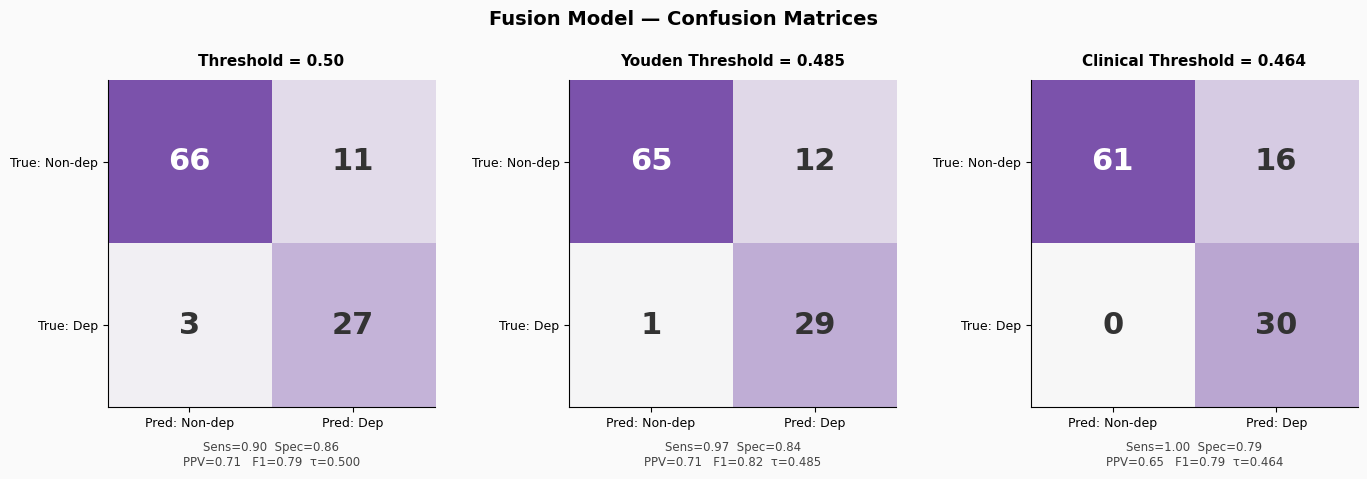

Saved: confusion_matrices.png


ValueError: Found input variables with inconsistent numbers of samples: [107, 46]

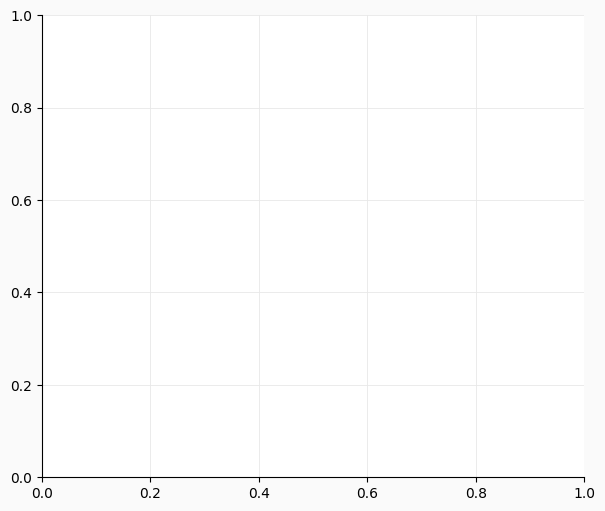

In [15]:
run_all_visualizations(
    y_bin            = y_bin,
    y_scr            = y_scr,
    schnet_probs     = schnet_probs,
    ling_probs       = ling_probs,
    loo_fusion_probs = loo_fusion_probs,
    X_meta           = X_meta,
    sev_pred_loo     = sev_pred_loo,
    best_t           = best_t,
    clin_t           = clin_t,
)